# **Project Name**    - Zomato Restaurant Segmentation Using Customer Reviews and Sentiment Analysis



##### **Project Type**    - Clustering
##### **Contribution**    - Individual
##### **Member Name**     - Rachana F Patil  

# **Project Summary -**

This project focuses on analysing Zomato restaurants using restaurant information and customer reviews to identify meaningful groups of restaurants based on their characteristics and customer experiences.

Two datasets are used: a restaurant metadata dataset containing details such as restaurant name, cost, collections, cuisines and timings, and a review dataset containing customer reviews, ratings, reviewer information, timestamps and pictures. These datasets are cleaned and combined using restaurant names as the linking key.

The review data is analysed using sentiment analysis to identify positive, negative and neutral customer opinions. VADER is used to calculate sentiment scores from review text. Additional features such as average ratings, percentage of positive and negative reviews, review length, reviewer activity and picture-related information are calculated and aggregated at the restaurant level.

The resulting restaurant-level dataset is used for exploratory analysis and feature engineering. Numerical and categorical information is prepared for machine learning through appropriate cleaning, transformation, scaling and dimensionality reduction techniques.

Since the objective is to discover groups of restaurants with similar characteristics rather than predict a predefined category, an unsupervised learning approach is followed. Multiple clustering algorithms, including K-Means, Agglomerative Clustering and Gaussian Mixture Models, are implemented and compared using suitable clustering evaluation metrics.

Hyperparameter tuning and validation are performed to identify a suitable clustering configuration. The selected model is further examined through cluster profiling and feature importance analysis to understand the characteristics that distinguish different restaurant groups.

The final outcome is intended to help identify restaurant segments based on customer satisfaction, ratings, sentiment and restaurant attributes. These findings can support Zomato in understanding customer experiences, identifying areas for improvement and developing more informed business strategies.

# **GitHub Link -**

https://github.com/RachanaFPatil/Zomato-Restaurant-Segmentation)

# **Problem Statement**


Zomato contains restaurant information and a large volume of customer reviews, but understanding the differences in restaurant performance and customer experiences can be challenging.

The objective of this project is to analyse restaurant attributes and customer feedback, identify sentiment patterns, and group restaurants with similar characteristics using unsupervised machine learning techniques.

The project aims to discover meaningful restaurant segments based on factors such as cost, cuisines, ratings and customer sentiment, and use these findings to suggest practical improvements and business strategies.

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import warnings, re, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED)
pd.set_option("display.max_columns", None, "display.max_colwidth", 80)

### Dataset Loading

In [2]:
# Load Dataset
# Raw files are only read, never overwritten
META_PATH = "Names_and_Metadata.csv"
REV_PATH = "Restaurant_reviews.csv"

meta_raw = pd.read_csv(META_PATH)
rev_raw = pd.read_csv(REV_PATH)

# Working copies
meta, rev = meta_raw.copy(), rev_raw.copy()

### Dataset First View

In [3]:
# Dataset First Look
display(meta.head())
display(rev.head())

,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,800,"Food Hygiene Rated Restaurants in Hyderabad, Corporate Favorites, Great Buff...","Chinese, Continental, Kebab, European, South Indian, North Indian","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gachibowli,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gachibowli,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-hotel-restaurant-gachibowli,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Beverages",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon-brew-company-gachibowli,"1,200","Best Bars & Pubs, Food Hygiene Rated Restaurants in Hyderabad, Top-Rated, Go...","Asian, Continental, North Indian, Chinese, Mediterranean","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12noon to 12midnight (Fri-Sat)"


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . had Saturday lunch , which was ...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. Service is very prompt. Food is...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx for the service by Pradeep and ...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only because of their behavior and sinc...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and basket mutton biryani. All are g...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
for name, df in [("Metadata", meta), ("Reviews", rev)]:
    print(f"{name}: {df.shape[0]} rows x {df.shape[1]} columns")

Metadata: 105 rows x 6 columns
Reviews: 10000 rows x 7 columns


### Dataset Information

In [5]:
# Dataset Info
meta.info()
print("-" * 60)
rev.info()

<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Name         105 non-null    str  
 1   Links        105 non-null    str  
 2   Cost         105 non-null    str  
 3   Collections  51 non-null     str  
 4   Cuisines     105 non-null    str  
 5   Timings      104 non-null    str  
dtypes: str(6)
memory usage: 21.5 KB
------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Restaurant  10000 non-null  str  
 1   Reviewer    9962 non-null   str  
 2   Review      9955 non-null   str  
 3   Rating      9962 non-null   str  
 4   Metadata    9962 non-null   str  
 5   Time        9962 non-null   str  
 6   Pictures    10000 non-null  int64
dtypes: int64(1), str(6)
memory usage: 3.8

#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("Metadata duplicate rows:", meta.duplicated().sum())
print("Metadata duplicate Names:", meta["Name"].duplicated().sum())
print("Reviews duplicate rows:", rev.duplicated().sum())
display(rev[rev.duplicated(keep=False)].sort_values(["Restaurant", "Reviewer"]).head(10))

Metadata duplicate rows: 0
Metadata duplicate Names: 0
Reviews duplicate rows: 36


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
8777,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8778,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8779,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8780,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8781,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8782,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8783,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8784,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8785,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8786,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
def missing_report(df):
    m = df.isnull().sum()
    return pd.DataFrame({"Missing": m, "Percent": (m / len(df) * 100).round(2)})[m > 0]

display(missing_report(meta))
display(missing_report(rev))

,Missing,Percent
Collections,54,51.43
Timings,1,0.95


,Missing,Percent
Reviewer,38,0.38
Review,45,0.45
Rating,38,0.38
Metadata,38,0.38
Time,38,0.38


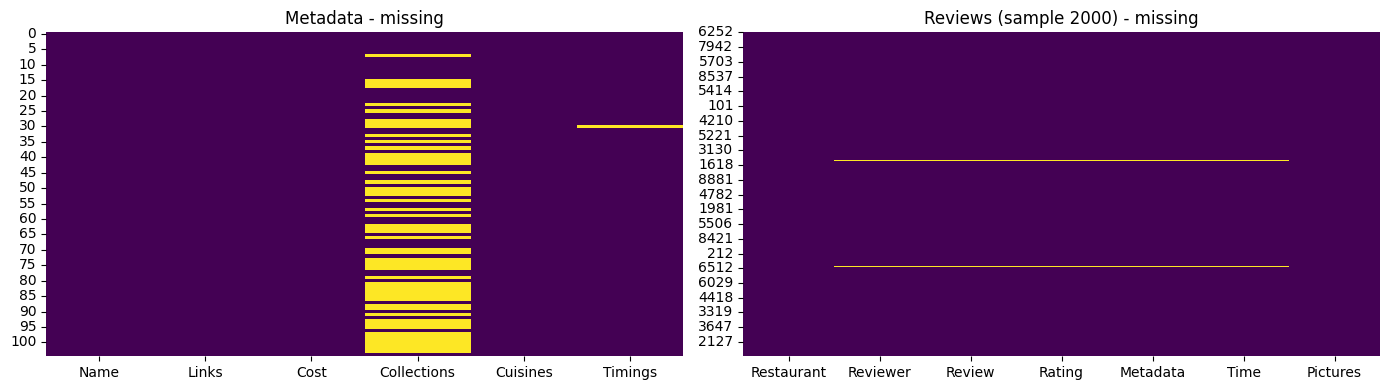

In [8]:
# Visualizing the missing values
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(meta.isnull(), cbar=False, ax=ax[0], cmap="viridis"); ax[0].set_title("Metadata - missing")
sns.heatmap(rev.sample(2000, random_state=SEED).isnull(), cbar=False, ax=ax[1], cmap="viridis"); ax[1].set_title("Reviews (sample 2000) - missing")
plt.tight_layout(); plt.show()

### What did you know about your dataset?

The project uses two datasets: restaurant metadata and customer reviews. The restaurant metadata contains 105 restaurants and 6 columns, including restaurant name, cost, collections, cuisines, timings and links. The reviews dataset contains 10,000 records and 7 columns, including restaurant name, reviewer details, review text, rating, timestamp and pictures.

Each restaurant has approximately 100 reviews. The datasets share restaurant names as a common key, allowing customer feedback to be connected with restaurant information. The data provides information about restaurant characteristics as well as customer experiences and opinions.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
print("Metadata:", list(meta.columns))
print("Reviews :", list(rev.columns))

Metadata: ['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']
Reviews : ['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']


In [10]:
# Dataset Describe
display(meta.describe(include="all").T)
display(rev.describe(include="all").T)

,count,unique,top,freq
Name,105,105,Beyond Flavours,1
Links,105,105,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,1
Cost,105,29,500,13
Collections,51,42,Food Hygiene Rated Restaurants in Hyderabad,4
Cuisines,105,92,"North Indian, Chinese",4
Timings,104,77,11 AM to 11 PM,6


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Restaurant,10000,100,Beyond Flavours,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reviewer,9962,7446,Ankita,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review,9955,9364,good,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9962,10,5,3832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Metadata,9962,2477,1 Review,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9962,9782,5/5/2019 22:39,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pictures,10000.0,NaN,NaN,NaN,0.7486,2.570381,0.0,0.0,0.0,0.0,64.0


### Variables Description

Restaurant Metadata:
- Name: Name of the restaurant.
- Links: Zomato page URL of the restaurant.
- Cost: Approximate cost for two people.
- Collections: Zomato collection or category associated with the restaurant.
- Cuisines: Types of cuisines served.
- Timings: Restaurant operating hours.

Customer Reviews:
- Restaurant: Name of the restaurant being reviewed.
- Reviewer: Name of the customer who submitted the review.
- Review: Written feedback provided by the customer.
- Rating: Customer rating, ranging from 1 to 5, including half-star values.
- Metadata: Reviewer-related information, such as number of reviews and followers.
- Time: Date and time when the review was submitted.
- Pictures: Number of pictures associated with the review.

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
for name, df in [("Metadata", meta), ("Reviews", rev)]:
    print(f"\n{name}")
    print(df.nunique().sort_values(ascending=False))

print("\nRating raw values:", sorted(rev["Rating"].dropna().astype(str).unique()))
print("Pictures value counts (top):\n", rev["Pictures"].value_counts().head())


Metadata
Name           105
Links          105
Cuisines        92
Timings         77
Collections     42
Cost            29
dtype: int64

Reviews
Time          9782
Review        9364
Reviewer      7446
Metadata      2477
Restaurant     100
Pictures        36
Rating          10
dtype: int64

Rating raw values: ['1', '1.5', '2', '2.5', '3', '3.5', '4', '4.5', '5', 'Like']
Pictures value counts (top):
 Pictures
0    8016
1     707
2     383
3     246
4     129
Name: count, dtype: int64


In [12]:
# Validate merge key: reviews.Restaurant -> metadata.Name
norm = lambda s: s.astype(str).str.strip().str.lower().str.replace(r"\s+", " ", regex=True)

meta_names, rev_names = set(norm(meta["Name"])), set(norm(rev["Restaurant"]))
print("Metadata names:", len(meta_names), "| Review restaurants:", len(rev_names))
print("Exact-match overlap:", len(meta_names & rev_names))
print("In reviews, not in metadata:", sorted(rev_names - meta_names))
print("In metadata, not in reviews:", len(meta_names - rev_names))
display(meta.loc[norm(meta["Name"]).isin(meta_names - rev_names), ["Name", "Cost", "Cuisines"]])

print("\nReviews per restaurant:")
print(rev.groupby("Restaurant").size().describe())
print("Restaurant null count in reviews:", rev["Restaurant"].isnull().sum())

# Cardinality check (expect one-to-many: metadata 1 -> reviews many)
test = rev.merge(meta, left_on="Restaurant", right_on="Name", how="left", validate="m:1", indicator=True)
print("\nMerged shape:", test.shape, "(reviews rows:", len(rev), ")")
print(test["_merge"].value_counts())

Metadata names: 105 | Review restaurants: 100
Exact-match overlap: 100
In reviews, not in metadata: []
In metadata, not in reviews: 5


,Name,Cost,Cuisines
100,IndiBlaze,600,"Fast Food, Salad"
101,Sweet Basket,200,"Bakery, Mithai"
102,Angaara Counts 3,500,"North Indian, Biryani, Chinese"
103,Wich Please,250,Fast Food
104,Republic Of Noodles - Lemon Tree Hotel,"1,700","Thai, Asian, Chinese, Malaysian"



Reviews per restaurant:
count    100.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
dtype: float64
Restaurant null count in reviews: 0

Merged shape: (10000, 14) (reviews rows: 10000 )
_merge
both          10000
left_only         0
right_only        0
Name: count, dtype: int64


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# ---------- 1. Reviews cleaning ----------
rev = rev_raw.copy()
n0 = len(rev)

# Diagnostics: confirm the "duplicates" are empty rows and find non-numeric ratings
empty_mask = rev[["Reviewer", "Review", "Rating", "Metadata", "Time"]].isnull().all(axis=1)
print("Fully empty rows:", empty_mask.sum(), "| duplicates among non-empty rows:", rev[~empty_mask].duplicated().sum())
print("Non-numeric Rating values:", rev.loc[pd.to_numeric(rev["Rating"], errors="coerce").isnull() & rev["Rating"].notnull(), "Rating"].unique())

rev = rev[~empty_mask].drop_duplicates().reset_index(drop=True)
rev["Rating"] = pd.to_numeric(rev["Rating"], errors="coerce")          # non-numeric -> NaN
rev["Review"] = rev["Review"].fillna("").astype(str).str.strip()
rev["Time"] = pd.to_datetime(rev["Time"], errors="coerce")

# Reviewer metadata -> numeric features
rev["reviewer_reviews"] = pd.to_numeric(rev["Metadata"].str.extract(r"(\d+)\s*Review")[0], errors="coerce")
rev["reviewer_followers"] = pd.to_numeric(rev["Metadata"].str.extract(r"(\d+)\s*Follower")[0], errors="coerce").fillna(0)

# ---------- 2. Restaurant metadata cleaning ----------
meta = meta_raw.copy()
meta["Cost"] = pd.to_numeric(meta["Cost"].astype(str).str.replace(",", ""), errors="coerce")
meta["Collections"] = meta["Collections"].fillna("None")
meta["Cuisines"] = meta["Cuisines"].fillna("Unknown")

# ---------- 3. Merge (reviews m:1 metadata) ----------
df = rev.merge(meta, left_on="Restaurant", right_on="Name", how="left", validate="m:1", indicator=True)
assert (df["_merge"] == "both").all(), "Unmatched reviews found"
df = df.drop(columns=["_merge", "Name"])

# Restaurants without reviews are kept at restaurant level, flagged
no_rev = meta.loc[~meta["Name"].isin(rev["Restaurant"]), "Name"].tolist()

print(f"\nReviews: {n0} -> {len(rev)} rows after cleaning")
print("Merged review-level shape:", df.shape)
print("Restaurants without reviews (kept, flagged):", no_rev)
print("\nRemaining nulls:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nRating distribution:\n", df["Rating"].value_counts(dropna=False).sort_index())
print("\nReviews per restaurant:\n", df.groupby("Restaurant").size().describe())
print("Review date range:", df["Time"].min(), "->", df["Time"].max())
display(df[["reviewer_reviews", "reviewer_followers", "Pictures", "Cost"]].describe().T)

Fully empty rows: 38 | duplicates among non-empty rows: 0
Non-numeric Rating values: <ArrowStringArray>
['Like']
Length: 1, dtype: str

Reviews: 10000 -> 9962 rows after cleaning
Merged review-level shape: (9962, 14)
Restaurants without reviews (kept, flagged): ['IndiBlaze', 'Sweet Basket', 'Angaara Counts 3', 'Wich Please', 'Republic Of Noodles - Lemon Tree Hotel']

Remaining nulls:
 Rating                1
reviewer_reviews      6
Timings             100
dtype: int64

Rating distribution:
 Rating
1.0    1735
1.5       9
2.0     684
2.5      19
3.0    1193
3.5      47
4.0    2373
4.5      69
5.0    3832
NaN       1
Name: count, dtype: int64

Reviews per restaurant:
 count    100.000000
mean      99.620000
std        2.733186
min       77.000000
25%      100.000000
50%      100.000000
75%      100.000000
max      100.000000
dtype: float64
Review date range: 2016-05-31 16:41:00 -> 2019-05-25 20:23:00


,count,mean,std,min,25%,50%,75%,max
reviewer_reviews,9956.0,23.959321,50.601613,0.0,1.0,4.0,22.0,1031.0
reviewer_followers,9962.0,162.994178,619.950232,0.0,1.0,7.0,63.0,13410.0
Pictures,9962.0,0.751456,2.574863,0.0,0.0,0.0,0.0,64.0
Cost,9962.0,871.531821,503.427308,150.0,500.0,700.0,1200.0,2800.0


In [16]:
pip install vaderSentiment

   ---------------------------------------- 0.0/126.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/126.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/126.0 kB ? eta -:--:--
   --- ------------------------------------ 10.2/126.0 kB ? eta -:--:--
   --- ------------------------------------ 10.2/126.0 kB ? eta -:--:--
   --- ------------------------------------ 10.2/126.0 kB ? eta -:--:--
   --- ------------------------------------ 10.2/126.0 kB ? eta -:--:--
   --------- ----------------------------- 30.7/126.0 kB 100.9 kB/s eta 0:00:01
   ------------ -------------------------- 41.0/126.0 kB 122.9 kB/s eta 0:00:01
   -------------------------------------  122.9/126.0 kB 379.3 kB/s eta 0:00:01
   -------------------------------------- 126.0/126.0 kB 322.3 kB/s eta 0:00:00



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# ---------- 1. Review-level sentiment (VADER on raw text; empty reviews -> NaN, not neutral) ----------
sia = SentimentIntensityAnalyzer()
has_text = df["Review"].str.len() > 0
df["compound"] = np.where(has_text, df["Review"].apply(lambda t: sia.polarity_scores(t)["compound"]), np.nan)
df["sentiment"] = pd.cut(df["compound"], [-1.01, -0.05, 0.05, 1.01], labels=["Negative", "Neutral", "Positive"])
df["review_len"] = df["Review"].str.split().str.len()

# Sanity check: sentiment should rise with star rating
print("Empty-text reviews:", (~has_text).sum())
print(df.groupby("Rating")["compound"].agg(["mean", "count"]).round(3))
print("Spearman(Rating, compound):", round(df[["Rating", "compound"]].corr(method="spearman").iloc[0, 1], 3))

# ---------- 2. Critic flag (reviewer experience, threshold from data) ----------
crit_thr = df["reviewer_reviews"].quantile(0.90)
df["is_critic"] = (df["reviewer_reviews"] >= crit_thr).astype(int)
df["reviewer_reviews"] = df["reviewer_reviews"].fillna(0)
print("Critic threshold (>= reviews):", crit_thr, "| critic share:", df["is_critic"].mean().round(3))

# ---------- 3. Restaurant-level aggregation (clustering unit) ----------
g = df.groupby("Restaurant")
rest = pd.DataFrame({
    "n_reviews": g.size(),
    "avg_rating": g["Rating"].mean(),
    "rating_std": g["Rating"].std(),
    "avg_compound": g["compound"].mean(),
    "pct_positive": g["sentiment"].apply(lambda s: (s == "Positive").mean()),
    "pct_negative": g["sentiment"].apply(lambda s: (s == "Negative").mean()),
    "pct_low_rating": g["Rating"].apply(lambda s: (s <= 2).mean()),
    "avg_review_len": g["review_len"].mean(),
    "avg_pictures": g["Pictures"].mean(),
    "pct_with_pictures": g["Pictures"].apply(lambda s: (s > 0).mean()),
    "avg_reviewer_followers": g["reviewer_followers"].mean(),
    "avg_reviewer_reviews": g["reviewer_reviews"].mean(),
    "pct_critic": g["is_critic"].mean(),
    "critic_avg_rating": g.apply(lambda x: x.loc[x["is_critic"] == 1, "Rating"].mean()),
    "pct_recent_12m": g["Time"].apply(lambda s: (s >= s.max() - pd.DateOffset(years=1)).mean()),
}).reset_index()

# Merge restaurant attributes (left join on all 105 so unreviewed restaurants stay visible)
rest_all = meta.merge(rest, left_on="Name", right_on="Restaurant", how="left", validate="1:1").drop(columns="Restaurant")
rest_all["has_reviews"] = rest_all["n_reviews"].notnull().astype(int)
rest_all["n_cuisines"] = rest_all["Cuisines"].str.split(",").str.len()
rest_all["n_collections"] = np.where(rest_all["Collections"] == "None", 0, rest_all["Collections"].str.count(",") + 1)

print("\nrest_all shape:", rest_all.shape, "| with reviews:", rest_all["has_reviews"].sum())
print("Nulls:\n", rest_all.isnull().sum()[rest_all.isnull().sum() > 0])
display(rest_all.describe().T.round(3))

Empty-text reviews: 7
         mean  count
Rating              
1.0    -0.336   1735
1.5    -0.114      9
2.0    -0.070    684
2.5     0.192     19
3.0     0.428   1192
3.5     0.750     47
4.0     0.772   2373
4.5     0.875     69
5.0     0.767   3826
Spearman(Rating, compound): 0.582
Critic threshold (>= reviews): 73.0 | critic share: 0.101

rest_all shape: (105, 24) | with reviews: 100
Nulls:
 Timings                    1
n_reviews                  5
avg_rating                 5
rating_std                 5
avg_compound               5
pct_positive               5
pct_negative               5
pct_low_rating             5
avg_review_len             5
avg_pictures               5
pct_with_pictures          5
avg_reviewer_followers     5
avg_reviewer_reviews       5
pct_critic                 5
critic_avg_rating         10
pct_recent_12m             5
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Cost,105.0,861.429,510.150,150.000,500.000,700.000,1200.000,2800.000
n_reviews,100.0,99.620,2.733,77.000,100.000,100.000,100.000,100.000
avg_rating,100.0,3.603,0.508,2.400,3.245,3.613,3.846,4.880
rating_std,100.0,1.378,0.254,0.498,1.237,1.430,1.549,1.854
avg_compound,100.0,0.477,0.232,-0.103,0.324,0.488,0.647,0.913
pct_positive,100.0,0.742,0.151,0.350,0.650,0.755,0.850,0.990
pct_negative,100.0,0.185,0.098,0.010,0.128,0.175,0.250,0.500
pct_low_rating,100.0,0.243,0.127,0.020,0.158,0.235,0.320,0.640
avg_review_len,100.0,50.303,22.647,10.130,33.495,47.920,64.690,102.240
avg_pictures,100.0,0.760,0.737,0.010,0.170,0.560,1.130,3.560


### What all manipulations have you done and insights you found?

The following data wrangling operations were performed:

1. Removed 38 fully empty rows and checked for duplicate records. No duplicate non-empty records were found.
2. Converted the Rating and Cost columns into numeric formats. The non-numeric rating value 'Like' was converted into a missing value.
3. Cleaned review text by replacing missing values with empty strings and removing extra whitespace.
4. Converted the Time column into datetime format.
5. Extracted reviewer review counts and follower counts from the Metadata column to create separate numerical features.
6. Handled missing values in Collections and Cuisines by assigning suitable labels.
7. Merged the restaurant and review datasets using restaurant names as the common key.
8. Applied VADER sentiment analysis to customer reviews to calculate compound sentiment scores and classify reviews as positive, negative or neutral.
9. Created additional features such as review length, critic identification, average rating, rating variation, positive and negative review percentages, picture statistics and reviewer statistics.
10. Aggregated review-level information into restaurant-level features and retained all 105 restaurants, including the five restaurants without reviews.

Key insights:
- The review dataset was reduced from 10,000 to 9,962 rows after cleaning.
- The merged review-level dataset contains 9,962 records and 14 columns.
- Reviews cover the period from May 2016 to May 2019.
- The average restaurant rating is approximately 3.60.
- Around 74.2% of reviews were classified as positive and 18.5% as negative.
- The Spearman correlation between star ratings and VADER sentiment scores is 0.582, indicating a moderate positive relationship.
- The average cost for two people is approximately ₹861.
- Five restaurants did not have customer reviews and were retained in the restaurant-level dataset for completeness.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

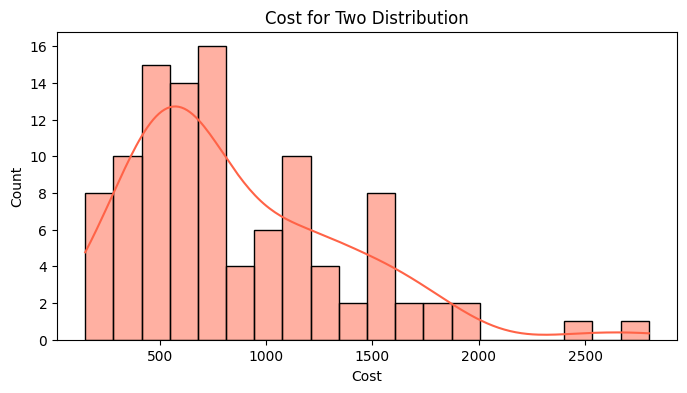

In [18]:
# Chart - 1 visualization code
plt.figure(figsize=(8, 4)); sns.histplot(rest_all["Cost"], bins=20, kde=True, color="tomato")
plt.title("Cost for Two Distribution"); plt.xlabel("Cost"); plt.show()

##### 1. Why did you pick the specific chart?

A histogram was chosen to understand how restaurant costs are distributed.

##### 2. What is/are the insight(s) found from the chart?

Most restaurants have a lower-to-mid-range cost, while a few are relatively expensive. The distribution is right-skewed.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This helps identify restaurant pricing segments and understand customer affordability, supporting better pricing and marketing decisions.

#### Chart - 2

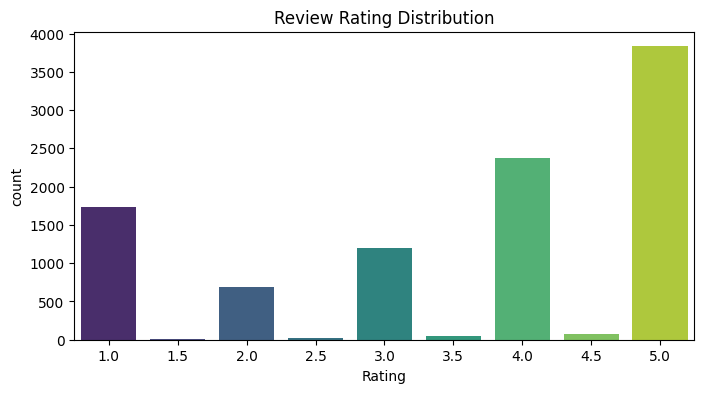

In [19]:
# Chart - 2 visualization code
plt.figure(figsize=(8, 4)); sns.countplot(x="Rating", data=df, palette="viridis")
plt.title("Review Rating Distribution"); plt.show()

##### 1. Why did you pick the specific chart?

A count plot was used to compare the frequency of different customer ratings.

##### 2. What is/are the insight(s) found from the chart?

5-star ratings are the most common (3,832), followed by 4-star ratings (2,373). This indicates generally positive customer feedback.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Restaurants can identify customer satisfaction levels and focus on improving areas receiving low ratings.

#### Chart - 3

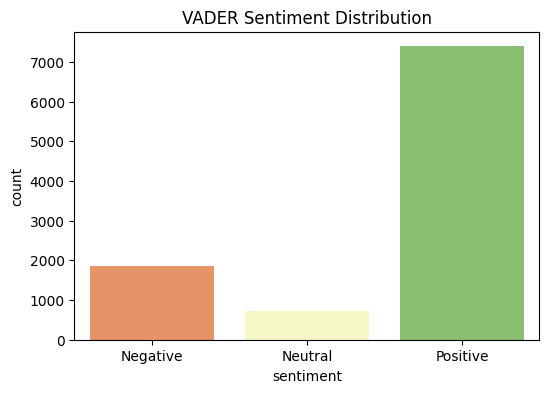

In [20]:
# Chart - 3 visualization code
plt.figure(figsize=(6, 4)); sns.countplot(x="sentiment", data=df, order=["Negative", "Neutral", "Positive"], palette="RdYlGn")
plt.title("VADER Sentiment Distribution"); plt.show()

##### 1. Why did you pick the specific chart?

A count plot was selected to compare positive, negative and neutral customer reviews.

##### 2. What is/are the insight(s) found from the chart?

Around 74.2% of reviews are positive, 18.5% negative and 7.3% neutral

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This helps restaurants understand customer opinions, identify dissatisfaction and improve their services.

#### Chart - 4

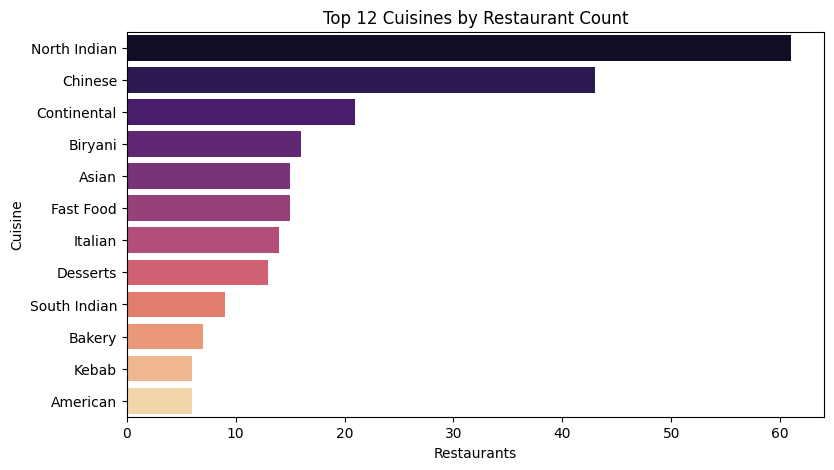

In [21]:
# Chart - 4 visualization code
cuisine_long = rest_all.assign(Cuisine=rest_all["Cuisines"].str.split(",")).explode("Cuisine")
cuisine_long["Cuisine"] = cuisine_long["Cuisine"].str.strip()
top_c = cuisine_long["Cuisine"].value_counts().head(12)
plt.figure(figsize=(9, 5)); sns.barplot(x=top_c.values, y=top_c.index, palette="magma")
plt.title("Top 12 Cuisines by Restaurant Count"); plt.xlabel("Restaurants"); plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart was chosen to compare the number of restaurants offering different cuisines and identify the most common ones.

##### 2. What is/are the insight(s) found from the chart?

North Indian cuisine has the highest restaurant count, followed by Chinese and Continental. American and Kebab cuisines have relatively fewer restaurants.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This helps businesses understand popular cuisine categories and identify less-represented segments that may offer opportunities for expansion.

#### Chart - 5

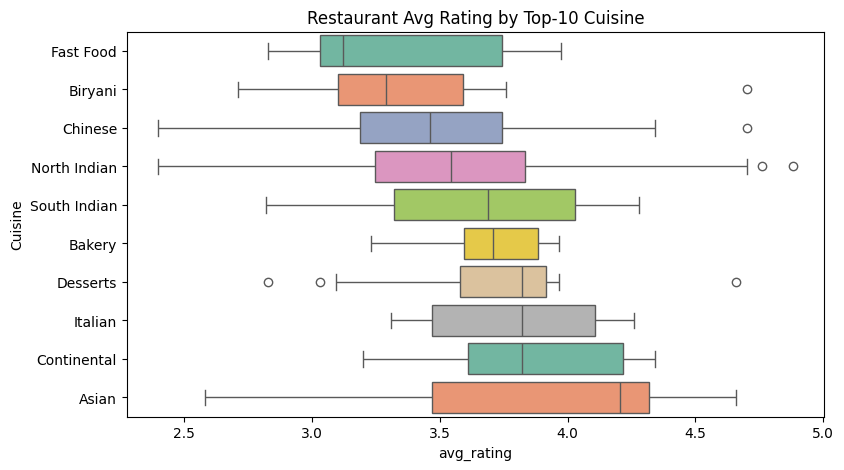

In [34]:
# Chart - 5 visualization code
cuisine_long = cuisine_long.reset_index(drop=True)
cc = cuisine_long[cuisine_long["Cuisine"].isin(top_c.index[:10])].dropna(subset=["avg_rating"])
order = cc.groupby("Cuisine")["avg_rating"].mean().sort_values().index
plt.figure(figsize=(9, 5)); sns.boxplot(x="avg_rating", y="Cuisine", data=cc, order=order, palette="Set2")
plt.title("Restaurant Avg Rating by Top-10 Cuisine"); plt.show()

##### 1. Why did you pick the specific chart?

A box plot was selected to compare rating distributions across cuisines, including their median ratings, variation and outliers.

##### 2. What is/are the insight(s) found from the chart?

Asian cuisine has the highest median rating among the displayed cuisines, while Fast Food has a relatively lower median. Ratings also vary considerably within some cuisine categories.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Restaurants can benchmark their ratings against competitors offering similar cuisines and identify areas where service or food quality needs improvement.

#### Chart - 6

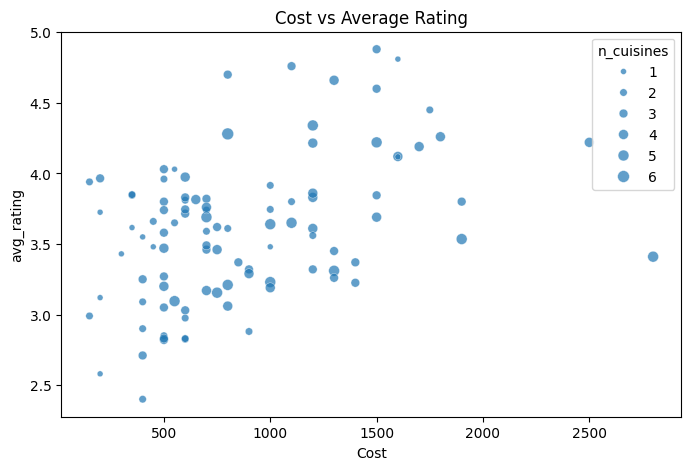

In [23]:
# Chart - 6 visualization code
plt.figure(figsize=(8, 5)); sns.scatterplot(x="Cost", y="avg_rating", size="n_cuisines", data=rest_all, alpha=0.7)
plt.title("Cost vs Average Rating"); plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot was used to examine the relationship between restaurant cost and average customer rating. Bubble size represents the number of cuisines offered.

##### 2. What is/are the insight(s) found from the chart?

Higher restaurant costs do not consistently result in higher ratings. Restaurants across different price ranges receive both high and low ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Restaurants can evaluate whether their pricing matches customer satisfaction and make pricing decisions based on value rather than cost alone.

#### Chart - 7

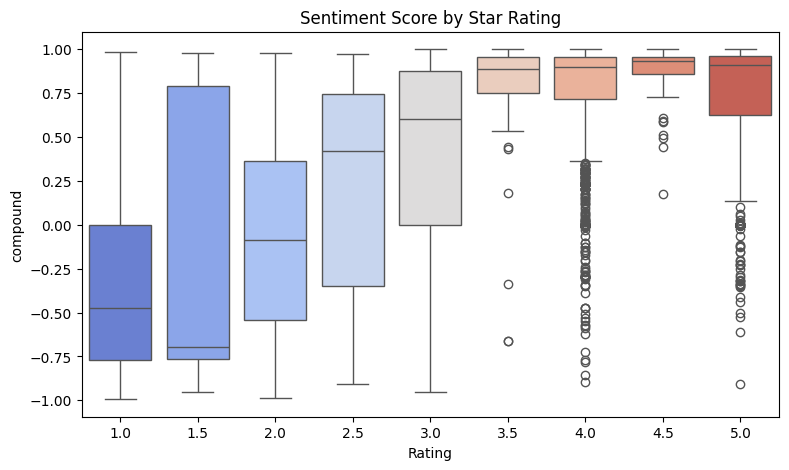

In [24]:
# Chart - 7 visualization code
plt.figure(figsize=(9, 5)); sns.boxplot(x="Rating", y="compound", data=df, palette="coolwarm")
plt.title("Sentiment Score by Star Rating"); plt.show()

##### 1. Why did you pick the specific chart?

A box plot was selected to compare sentiment scores across different star ratings and understand how customer sentiment changes with ratings.

##### 2. What is/are the insight(s) found from the chart?

Lower ratings generally have negative sentiment scores, while higher ratings show positive sentiment. This indicates a relationship between customer ratings and review sentiment

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Restaurants can use sentiment analysis to identify dissatisfaction beyond star ratings and understand areas that need improvement

#### Chart - 8

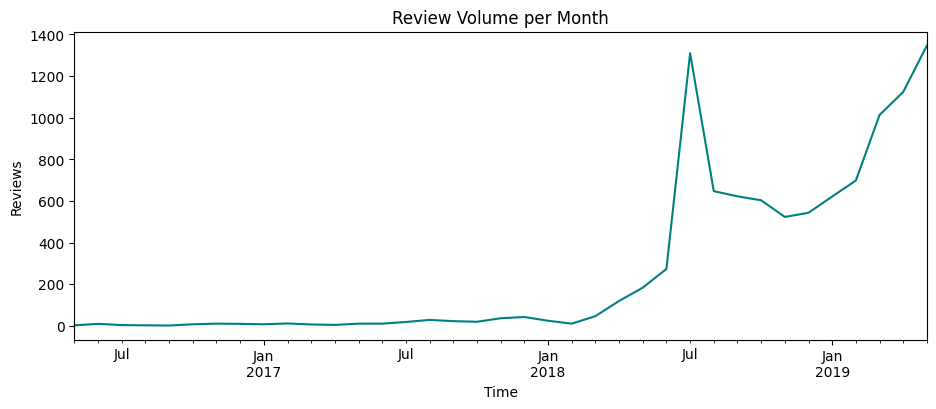

In [33]:
monthly = df.set_index("Time").resample("ME").size()
plt.figure(figsize=(11, 4)); monthly.plot(color="teal")
plt.title("Review Volume per Month"); plt.ylabel("Reviews"); plt.show()

##### 1. Why did you pick the specific chart?

A line chart was chosen to observe changes in customer review activity over time and identify periods with higher or lower engagement.

##### 2. What is/are the insight(s) found from the chart?

Review volume increased significantly from mid-2018 onwards, with noticeable peaks in July 2018 and May 2019.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Tracking review activity helps businesses monitor customer engagement and evaluate whether marketing campaigns or service changes influence customer feedback.

#### Chart - 9

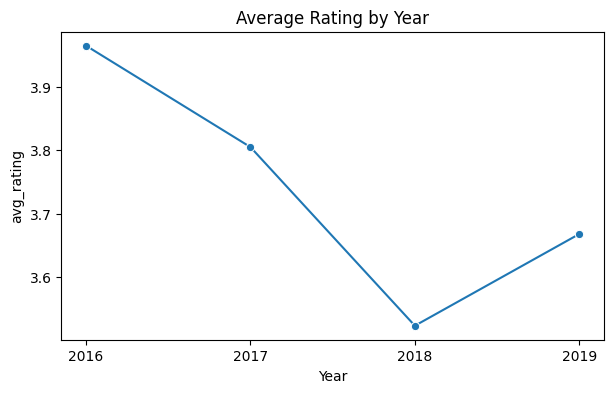

   Time  avg_rating     n
0  2016    3.965116    43
1  2017    3.805164   213
2  2018    3.523353  4903
3  2019    3.668055  4803


In [26]:
# Chart - 9 visualization code
yr = df.groupby(df["Time"].dt.year).agg(avg_rating=("Rating", "mean"), n=("Rating", "size")).reset_index()
plt.figure(figsize=(7, 4)); sns.lineplot(x="Time", y="avg_rating", data=yr, marker="o")
plt.xticks(yr["Time"]); plt.title("Average Rating by Year"); plt.xlabel("Year"); plt.show()
print(yr)

##### 1. Why did you pick the specific chart?

A line chart was used to track yearly changes in average customer ratings and identify trends in customer satisfaction.

##### 2. What is/are the insight(s) found from the chart?

Average ratings declined from 3.97 in 2016 to 3.52 in 2018, before improving to 3.67 in 2019. The 2016 and 2017 results are based on fewer reviews.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This helps restaurants monitor changes in customer satisfaction over time and identify when service improvements may be needed.

#### Chart - 10

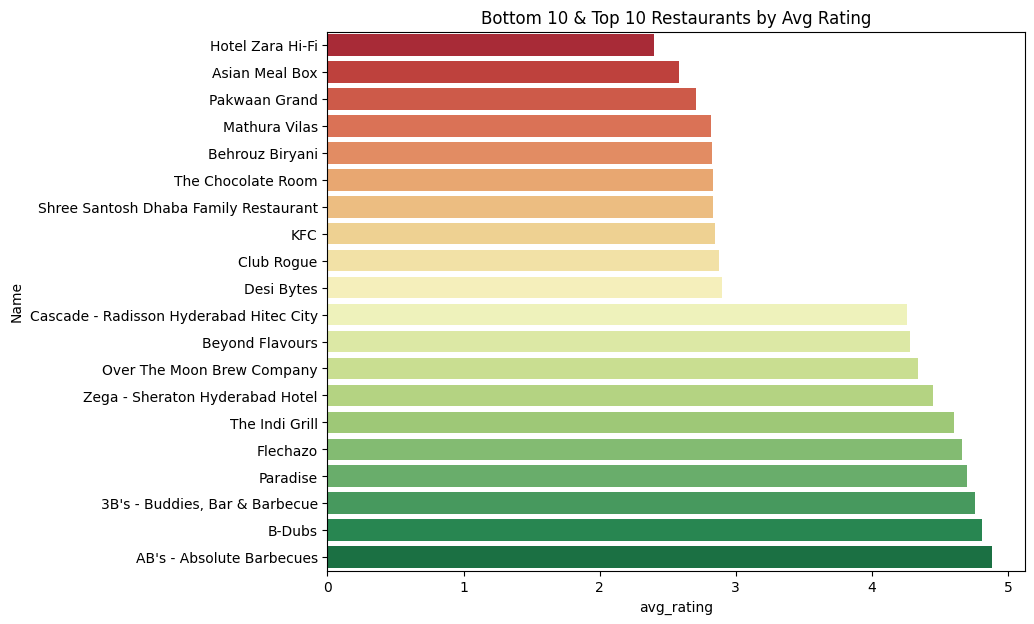

In [27]:
# Chart - 10 visualization code
r = rest_all.dropna(subset=["avg_rating"]).sort_values("avg_rating")
tb = pd.concat([r.head(10), r.tail(10)])
plt.figure(figsize=(9, 7)); sns.barplot(x="avg_rating", y="Name", data=tb, palette="RdYlGn")
plt.title("Bottom 10 & Top 10 Restaurants by Avg Rating"); plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart was chosen to compare the highest- and lowest-rated restaurants and make their ranking easy to understand.

##### 2. What is/are the insight(s) found from the chart?

AB's - Absolute Barbecues has the highest average rating, while Hotel Zara Hi-Fi has the lowest. The chart highlights clear differences in customer satisfaction.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Highly rated restaurants can identify what they are doing well, while lower-rated restaurants can use the comparison to identify areas needing improvement.

#### Chart - 11

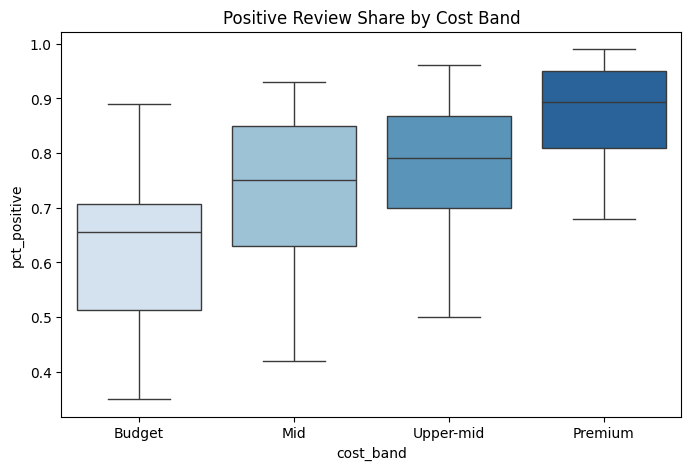

In [28]:
# Chart - 11 visualization code
rest_all["cost_band"] = pd.qcut(rest_all["Cost"], 4, labels=["Budget", "Mid", "Upper-mid", "Premium"])
plt.figure(figsize=(8, 5)); sns.boxplot(x="cost_band", y="pct_positive", data=rest_all, palette="Blues")
plt.title("Positive Review Share by Cost Band"); plt.show()

##### 1. Why did you pick the specific chart?

A box plot was selected to compare the distribution of positive review percentages across different restaurant price categories.

##### 2. What is/are the insight(s) found from the chart?

Premium restaurants have the highest median positive review share, followed by upper-mid, mid and budget restaurants. However, positive feedback varies within each category.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This helps restaurants understand how customer sentiment differs across price segments and evaluate whether their offerings provide good value.

#### Chart - 12

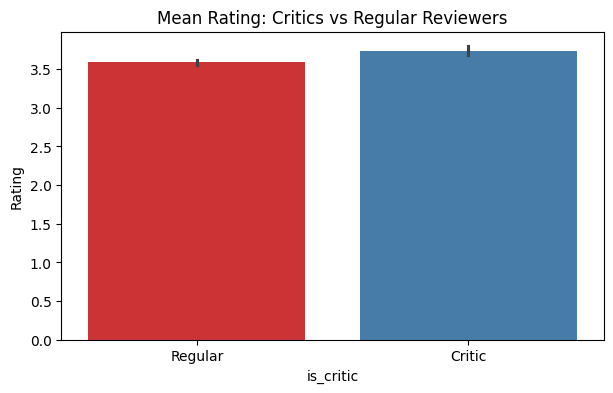

In [29]:
# Chart - 12 visualization code
plt.figure(figsize=(7, 4)); sns.barplot(x="is_critic", y="Rating", data=df, palette="Set1", errorbar="ci")
plt.xticks([0, 1], ["Regular", "Critic"]); plt.title("Mean Rating: Critics vs Regular Reviewers"); plt.show()

##### 1. Why did you pick the specific chart?

A bar chart was used to compare the average ratings given by critics and regular reviewers.

##### 2. What is/are the insight(s) found from the chart?

Critics give slightly higher average ratings than regular reviewers. However, the difference is relatively small.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.


Understanding differences in reviewer behaviour helps restaurants interpret feedback from different customer groups and make better service decisions.

#### Chart - 13

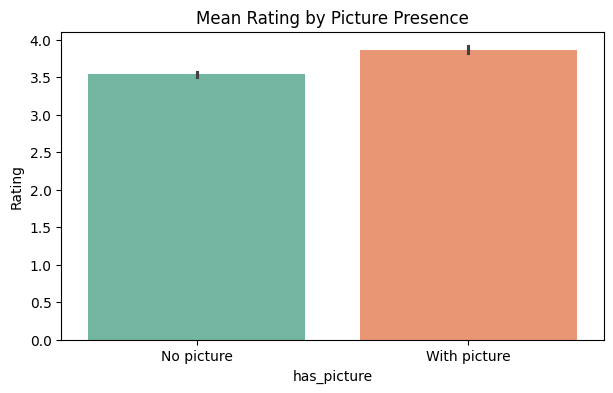

In [30]:
# Chart - 13 visualization code
df["has_picture"] = (df["Pictures"] > 0).astype(int)
plt.figure(figsize=(7, 4)); sns.barplot(x="has_picture", y="Rating", data=df, palette="Set2", errorbar="ci")
plt.xticks([0, 1], ["No picture", "With picture"]); plt.title("Mean Rating by Picture Presence"); plt.show()

##### 1. Why did you pick the specific chart?

A bar chart was selected to compare average restaurant ratings for reviews with and without pictures

##### 2. What is/are the insight(s) found from the chart?

Reviews with pictures have a higher average rating (approximately 3.9) than reviews without pictures (approximately 3.5).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Visual content may encourage customer engagement and improve restaurant visibility. Restaurants can encourage customers to share food pictures to strengthen their online presence.

#### Chart - 14 - Correlation Heatmap

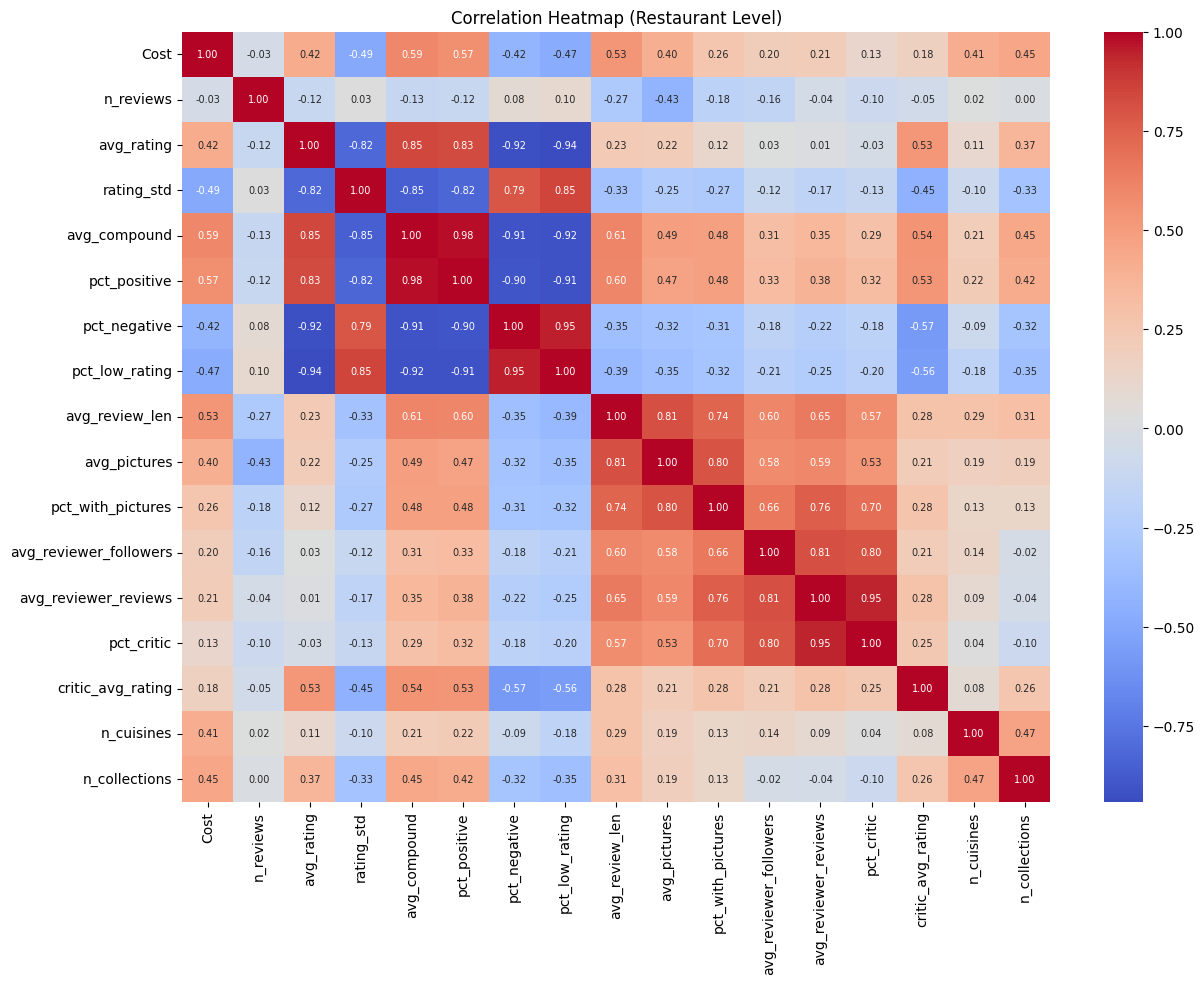

In [31]:
# Correlation Heatmap visualization code
num_cols = rest_all.select_dtypes("number").drop(columns=["has_reviews", "pct_recent_12m"]).columns
plt.figure(figsize=(14, 10)); sns.heatmap(rest_all[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Correlation Heatmap (Restaurant Level)"); plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap was used to identify relationships between numerical restaurant features and understand which variables are strongly related.

##### 2. What is/are the insight(s) found from the chart?

- Average rating and average sentiment have a strong positive correlation (0.85).
- Positive review percentage is strongly related to average sentiment (0.98).
- Negative review percentage is strongly negatively related to average rating (-0.92).

#### Chart - 15 - Pair Plot

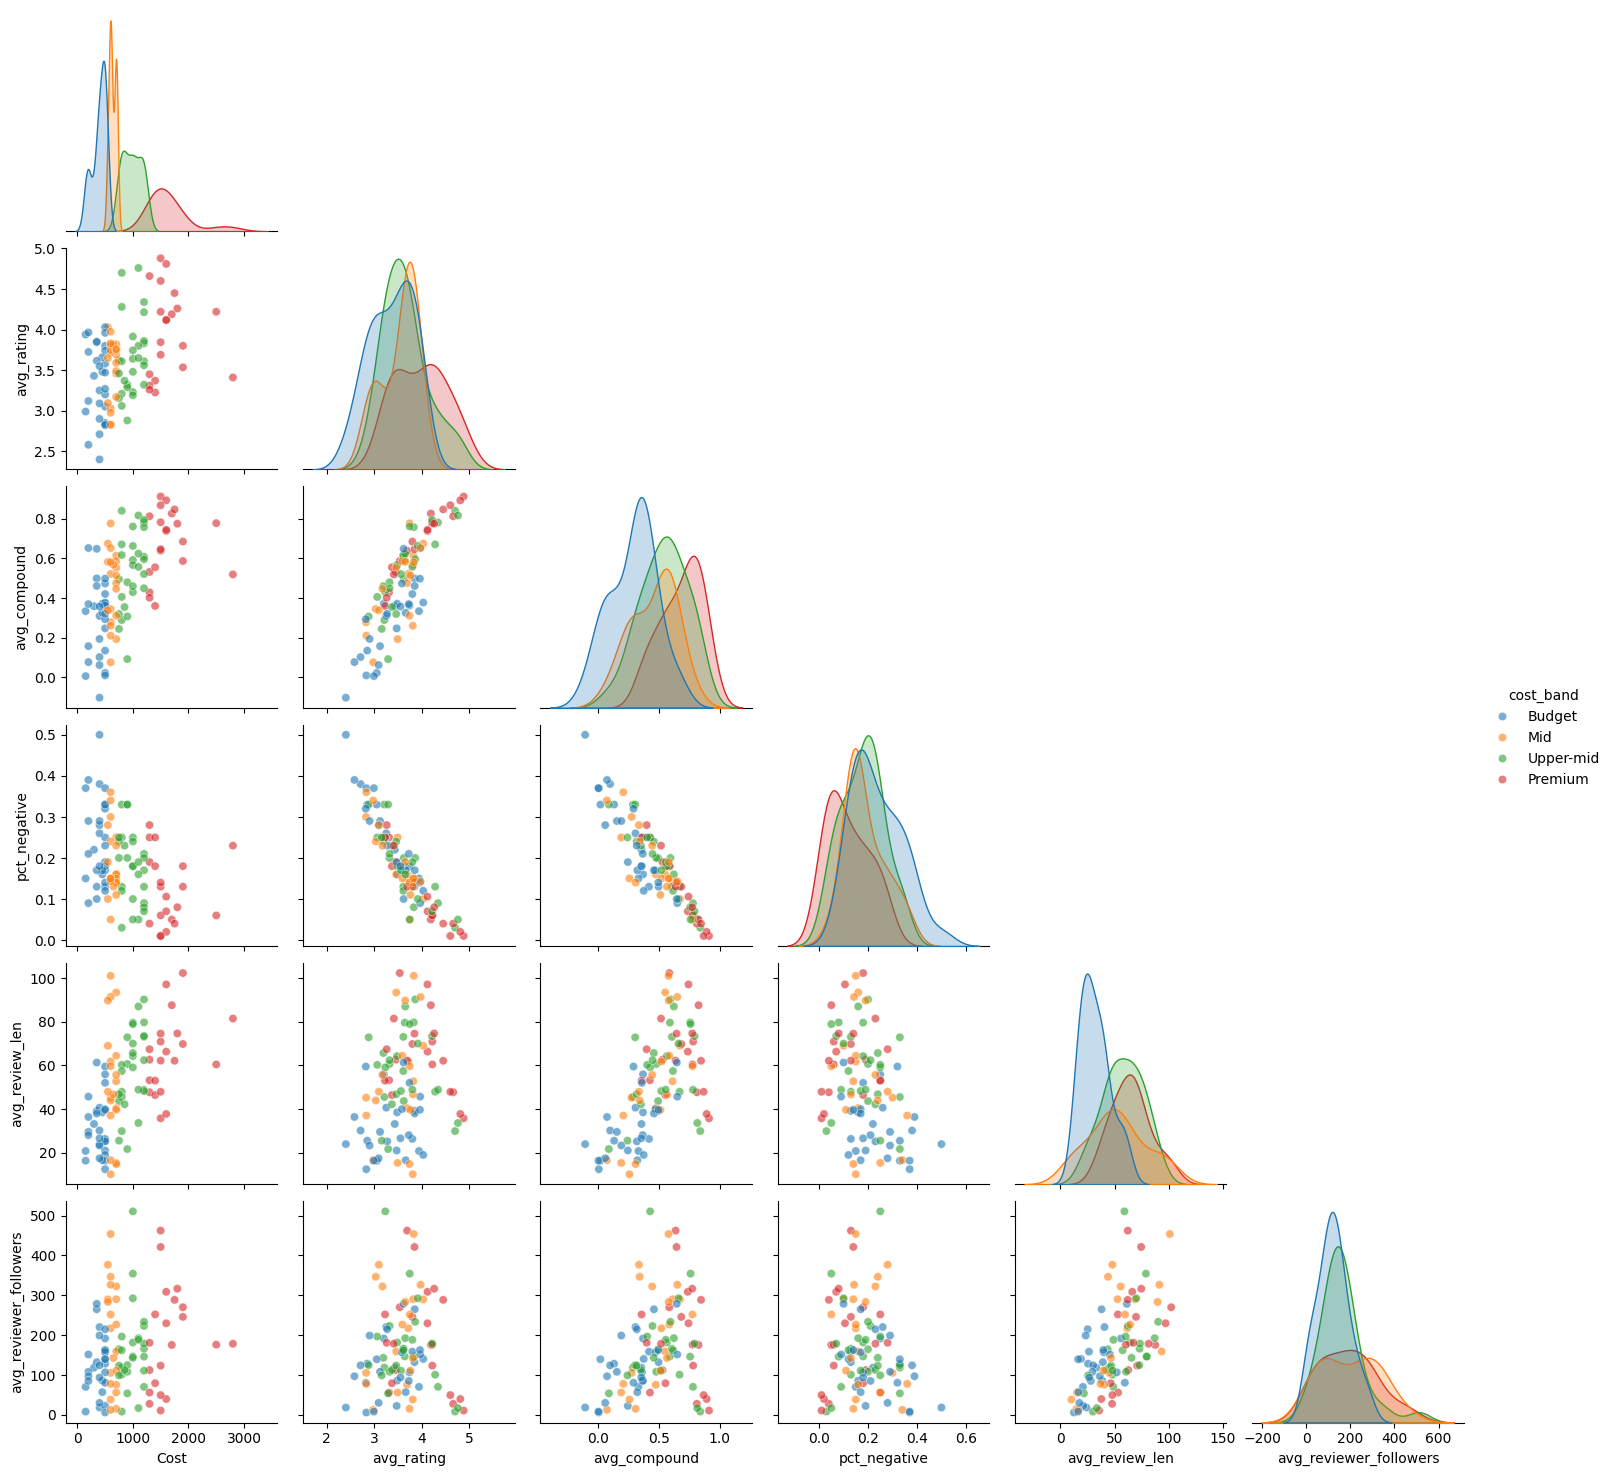

In [32]:
# Pair Plot visualization code
pp_cols = ["Cost", "avg_rating", "avg_compound", "pct_negative", "avg_review_len", "avg_reviewer_followers"]
sns.pairplot(rest_all[pp_cols + ["cost_band"]].dropna(), hue="cost_band", corner=True, plot_kws={"alpha": 0.6})
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot was selected to visualize relationships and distributions among cost, ratings, sentiment, negative reviews, review length and reviewer followers across price categories.

##### 2. What is/are the insight(s) found from the chart?

Average rating increases with sentiment and decreases as negative review percentage increases. The price categories overlap considerably, indicating that cost alone does not determine customer satisfaction.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

- Critics and regular reviewers give different restaurant ratings.
- Restaurant cost is related to average customer ratings.
- Reviews containing pictures have a different sentiment distribution from reviews without pictures.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- H₀: There is no significant difference in ratings given by critics and regular reviewers.
- H₁: There is a significant difference in their ratings.

#### 2. Perform an appropriate statistical test.

In [35]:
# Perform Statistical Test to obtain P-Value
from scipy import stats
alpha = 0.05

crit = df.loc[df["is_critic"] == 1, "Rating"].dropna()
reg = df.loc[df["is_critic"] == 0, "Rating"].dropna()

u, p = stats.mannwhitneyu(crit, reg, alternative="two-sided")
rbc = 2 * u / (len(crit) * len(reg)) - 1   # rank-biserial effect size

print(f"Critics n={len(crit)}, median={crit.median()}, mean={crit.mean():.3f}")
print(f"Regular n={len(reg)}, median={reg.median()}, mean={reg.mean():.3f}")
print(f"U={u:.1f}, p-value={p:.5f}, rank-biserial={rbc:.3f}")
print("Reject H0" if p < alpha else "Fail to reject H0")

Critics n=1004, median=4.0, mean=3.737
Regular n=8957, median=4.0, mean=3.586
U=4247414.0, p-value=0.00269, rank-biserial=-0.055
Reject H0


##### Which statistical test have you done to obtain P-Value?

Mann–Whitney U test. The p-value is 0.00269, which is below 0.05. Therefore, we reject the null hypothesis.

##### Why did you choose the specific statistical test?

The test was chosen because it compares two independent groups and does not require the rating data to follow a normal distribution.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- H₀: Average restaurant ratings do not differ significantly across cost categories.
- H₁: At least one cost category has a significantly different rating distribution.

#### 2. Perform an appropriate statistical test.

In [36]:
# Perform Statistical Test to obtain P-Value
rest_all["cost_band"] = pd.qcut(rest_all["Cost"], 4, labels=["Budget", "Mid", "Upper-mid", "Premium"])
tmp = rest_all.dropna(subset=["avg_rating"])
groups = [g["avg_rating"].values for _, g in tmp.groupby("cost_band", observed=True)]

h, p = stats.kruskal(*groups)
eps2 = (h - len(groups) + 1) / (len(tmp) - len(groups))   # epsilon-squared effect size
rho, p_rho = stats.spearmanr(tmp["Cost"], tmp["avg_rating"])

print(tmp.groupby("cost_band", observed=True)["avg_rating"].agg(["count", "median", "mean"]).round(3))
print(f"H={h:.3f}, p-value={p:.5f}, epsilon^2={eps2:.3f}")
print(f"Supporting Spearman(Cost, avg_rating): rho={rho:.3f}, p={p_rho:.5f}")
print("Reject H0" if p < alpha else "Fail to reject H0")

           count  median   mean
cost_band                      
Budget        30   3.450  3.357
Mid           21   3.690  3.526
Upper-mid     28   3.610  3.646
Premium       21   4.118  3.973
H=13.693, p-value=0.00335, epsilon^2=0.111
Supporting Spearman(Cost, avg_rating): rho=0.383, p=0.00009
Reject H0


##### Which statistical test have you done to obtain P-Value?

Kruskal–Wallis test. The p-value is 0.00335, below 0.05. Therefore, we reject the null hypothesis.

##### Why did you choose the specific statistical test?

It compares rating distributions across more than two independent cost groups without assuming normally distributed data.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- H₀: Picture presence and review sentiment are independent.
- H₁: Picture presence and review sentiment are significantly associated.

#### 2. Perform an appropriate statistical test.

In [37]:
# Perform Statistical Test to obtain P-Value
df["has_picture"] = (df["Pictures"] > 0).astype(int)
ct = pd.crosstab(df["has_picture"], df["sentiment"])
chi2, p, dof, exp = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

print(ct)
print("Row % :\n", (ct.div(ct.sum(axis=1), axis=0) * 100).round(2))
print("Min expected count:", exp.min().round(2))
print(f"chi2={chi2:.3f}, dof={dof}, p-value={p:.5f}, Cramer's V={cramers_v:.3f}")
print("Reject H0" if p < alpha else "Fail to reject H0")

sentiment    Negative  Neutral  Positive
has_picture                             
0                1672      687      5612
1                 175       30      1779
Row % :
 sentiment    Negative  Neutral  Positive
has_picture                             
0               20.98     8.62     70.41
1                8.82     1.51     89.67
Min expected count: 142.9
chi2=317.295, dof=2, p-value=0.00000, Cramer's V=0.179
Reject H0


##### Which statistical test have you done to obtain P-Value?

Chi-square test of independence. The p-value is below 0.05, so we reject the null hypothesis.

##### Why did you choose the specific statistical test?

It was chosen because both variables are categorical. It helps determine whether review sentiment is associated with the presence of pictures.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [38]:
# Handling Missing Values & Missing Value Imputation
DROP_COLS = ["pct_recent_12m"]   # near-constant (sampling artifact)
rest_model = rest_all[rest_all["has_reviews"] == 1].drop(columns=DROP_COLS).reset_index(drop=True)
unreviewed = rest_all[rest_all["has_reviews"] == 0].reset_index(drop=True)   # kept aside

# critic_avg_rating: NaN where a restaurant has no critic review -> median impute, with indicator
rest_model["critic_missing"] = rest_model["critic_avg_rating"].isnull().astype(int)
rest_model["critic_avg_rating"] = rest_model["critic_avg_rating"].fillna(rest_model["critic_avg_rating"].median())
rest_model["rating_std"] = rest_model["rating_std"].fillna(rest_model["rating_std"].median())

print("Modelling set:", rest_model.shape, "| unreviewed held aside:", len(unreviewed))
print("Remaining nulls (excluding Timings):\n", rest_model.drop(columns="Timings").isnull().sum().loc[lambda s: s > 0])

Modelling set: (100, 25) | unreviewed held aside: 5
Remaining nulls (excluding Timings):
 Series([], dtype: int64)


#### What all missing value imputation techniques have you used and why did you use those techniques?

Missing values in critic_avg_rating and rating_std were replaced with their median values. A separate critic_missing indicator was created to preserve information about missing critic ratings. Five restaurants without reviews were kept aside rather than included in the modelling dataset.

### 2. Handling Outliers

Outliers per feature (IQR rule):
 Cost                      2
avg_rating                3
rating_std                3
pct_positive              1
pct_negative              1
pct_low_rating            1
avg_pictures              4
pct_with_pictures         1
avg_reviewer_followers    3
avg_reviewer_reviews      1
critic_avg_rating         5
n_collections             7
dtype: int64


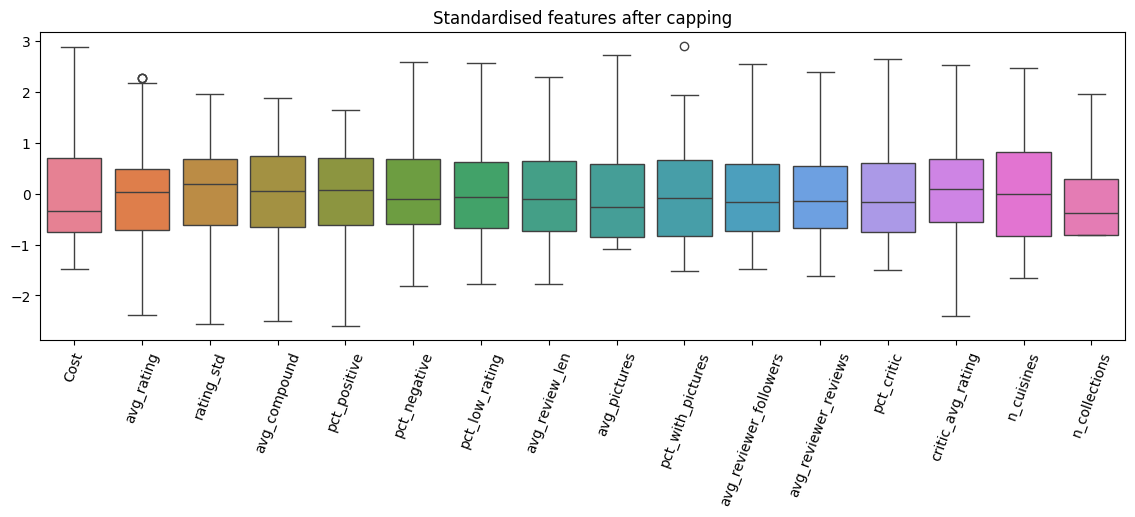

In [39]:
# Handling Outliers & Outlier treatments
NUM_FEATS = ["Cost", "avg_rating", "rating_std", "avg_compound", "pct_positive", "pct_negative", "pct_low_rating",
             "avg_review_len", "avg_pictures", "pct_with_pictures", "avg_reviewer_followers", "avg_reviewer_reviews",
             "pct_critic", "critic_avg_rating", "n_cuisines", "n_collections"]

q1, q3 = rest_model[NUM_FEATS].quantile(0.25), rest_model[NUM_FEATS].quantile(0.75)
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out_cnt = ((rest_model[NUM_FEATS] < lo) | (rest_model[NUM_FEATS] > hi)).sum()
print("Outliers per feature (IQR rule):\n", out_cnt[out_cnt > 0])

# Winsorize (cap) instead of dropping: only 100 restaurants, each is a real business
rest_model[NUM_FEATS] = rest_model[NUM_FEATS].clip(lower=lo, upper=hi, axis=1)

plt.figure(figsize=(14, 4)); sns.boxplot(data=(rest_model[NUM_FEATS] - rest_model[NUM_FEATS].mean()) / rest_model[NUM_FEATS].std())
plt.xticks(rotation=70); plt.title("Standardised features after capping"); plt.show()

##### What all outlier treatment techniques have you used and why did you use those techniques?

The IQR method was used to detect outliers. Instead of removing them, Winsorization was applied by capping values at the lower and upper IQR limits. This preserves genuine restaurant data while reducing the influence of extreme values.

### 3. Categorical Encoding

In [40]:
# Encode your categorical columns
from sklearn.preprocessing import MultiLabelBinarizer

# Cuisines: multi-hot for cuisines served by >= 5 restaurants (rare ones ignored to avoid sparse noise)
cuis_lists = rest_model["Cuisines"].str.split(",").apply(lambda l: [c.strip() for c in l])
cnt = pd.Series([c for l in cuis_lists for c in l]).value_counts()
keep = cnt[cnt >= 5].index.tolist()
mlb = MultiLabelBinarizer(classes=keep)
cuis_df = pd.DataFrame(mlb.fit_transform(cuis_lists.apply(lambda l: [c for c in l if c in keep])),
                       columns=["cuis_" + c.replace(" ", "_") for c in keep])

# Collections: flag for key Zomato tags
for tag, col in [("Gold", "col_gold"), ("Hygiene", "col_hygiene"), ("Top-Rated", "col_toprated"), ("Bars", "col_bars")]:
    rest_model[col] = rest_model["Collections"].str.contains(tag, case=False).astype(int)

# Cost band (ordinal)
rest_model["cost_band"] = pd.qcut(rest_model["Cost"], 4, labels=False)

rest_model = pd.concat([rest_model, cuis_df], axis=1)
CUIS_FEATS, COL_FEATS = cuis_df.columns.tolist(), ["col_gold", "col_hygiene", "col_toprated", "col_bars"]
print("Cuisines kept:", keep); print(rest_model.shape)

Cuisines kept: ['North Indian', 'Chinese', 'Continental', 'Biryani', 'Asian', 'Italian', 'Desserts', 'Fast Food', 'South Indian', 'Kebab', 'American', 'Mughlai', 'Andhra', 'Bakery', 'Cafe', 'Mediterranean', 'Beverages', 'Burger']
(100, 47)


#### What all categorical encoding techniques have you used & why did you use those techniques?

Multi-hot encoding was used for cuisines, retaining cuisines offered by at least five restaurants. Collection tags such as Gold, Hygiene, Top-Rated and Bars were converted into binary flags. Cost was divided into four ordinal bands using quantile-based binning.

### 4. Textual Data Preprocessing


#### 1. Expand Contraction

In [41]:
# Expand Contraction
import nltk
for pkg in ["stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng", "averaged_perceptron_tagger"]:
    nltk.download(pkg, quiet=True)

CONTR = {"won't": "will not", "can't": "can not", "n't": " not", "'re": " are", "'s": " is", "'d": " would",
         "'ll": " will", "'ve": " have", "'m": " am"}
def expand(t):
    for k, v in CONTR.items():
        t = re.sub(k, v, t, flags=re.I)
    return t

df["clean"] = df["Review"].apply(expand)
print(df["clean"].iloc[:3].tolist())

['The ambience was good, food was quite good . had Saturday lunch , which was cost effective .\nGood place for a sate brunch. One can also chill with friends and or parents.\nWaiter Soumen Das was really courteous and helpful.', 'Ambience is too good for a pleasant evening. Service is very prompt. Food is good. Over all a good experience. Soumen Das - kudos to the service', 'A must try.. great food great ambience. Thnx for the service by Pradeep and Subroto. My personal recommendation is Penne Alfredo Pasta:) ....... Also the music in the background is amazing.']


#### 2. Lower Casing

In [42]:
# Lower Casing
df["clean"] = df["clean"].str.lower()

#### 3. Removing Punctuations

In [43]:
# Remove Punctuations
df["clean"] = df["clean"].str.replace(r"[^\w\s]", " ", regex=True).str.replace("_", " ")

#### 4. Removing URLs & Removing words and digits contain digits.

In [44]:
# Remove URLs & Remove words and digits contain digits
df["clean"] = (df["clean"].str.replace(r"http\S+|www\.\S+", " ", regex=True)
                          .str.replace(r"\w*\d\w*", " ", regex=True))

#### 5. Removing Stopwords & Removing White spaces

In [45]:
# Remove Stopwords
from nltk.corpus import stopwords
STOP = set(stopwords.words("english")) - {"not", "no", "nor", "very", "too", "never"}   # keep sentiment-bearing words
df["clean"] = df["clean"].apply(lambda t: " ".join(w for w in t.split() if w not in STOP))

In [46]:
# Remove White spaces
df["clean"] = df["clean"].str.replace(r"\s+", " ", regex=True).str.strip()

#### 6. Rephrase Text

In [49]:
# Rephrase Text
# Collapse elongated words (e.g. "goooood" -> "good") and drop single-character tokens
elong = re.compile(r"(.)\1{2,}")
df["clean"] = df["clean"].apply(lambda t: " ".join(w for w in elong.sub(r"\1", t).split() if len(w) > 1))
print(df[["Review", "clean"]].sample(5, random_state=SEED))

                                                                               Review  \
6448                                                                             good   
6831  My exp with the place was a bit different from many other reviews. Went for ...   
8451  awesome place to be during evenings, must try kunda biryani it was well cook...   
39    I came here with my parents. We ordered for Thai peneer tikka, kaju pulao an...   
7458  Very very disappointed.\nFood taste was not up to the mark.\nIt was worst in...   

                                                                                clean  
6448                                                                             good  
6831  exp place bit different many reviews went lunch wifey place seemed suitable ...  
8451  awesome place evenings must try kunda biryani well cooked nonveg starters pl...  
39    came parents ordered thai peneer tikka kaju pulao veg biryani kaju pulao veg...  
7458  very very disappoin

#### 7. Tokenization

In [50]:
# Tokenization
from nltk.tokenize import RegexpTokenizer
tok = RegexpTokenizer(r"[a-z]+")
df["tokens"] = df["clean"].apply(tok.tokenize)
print(df["tokens"].iloc[:3].tolist())

[['ambience', 'good', 'food', 'quite', 'good', 'saturday', 'lunch', 'cost', 'effective', 'good', 'place', 'sate', 'brunch', 'one', 'also', 'chill', 'friends', 'parents', 'waiter', 'soumen', 'das', 'really', 'courteous', 'helpful'], ['ambience', 'too', 'good', 'pleasant', 'evening', 'service', 'very', 'prompt', 'food', 'good', 'good', 'experience', 'soumen', 'das', 'kudos', 'service'], ['must', 'try', 'great', 'food', 'great', 'ambience', 'thnx', 'service', 'pradeep', 'subroto', 'personal', 'recommendation', 'penne', 'alfredo', 'pasta', 'also', 'music', 'background', 'amazing']]


#### 8. Text Normalization

In [51]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
from nltk.stem import WordNetLemmatizer
lem = WordNetLemmatizer()
df["lemmas"] = df["tokens"].apply(lambda ts: [lem.lemmatize(w) for w in ts])
df["clean_text"] = df["lemmas"].str.join(" ")
print(df["clean_text"].iloc[:3].tolist())

['ambience good food quite good saturday lunch cost effective good place sate brunch one also chill friend parent waiter soumen da really courteous helpful', 'ambience too good pleasant evening service very prompt food good good experience soumen da kudos service', 'must try great food great ambience thnx service pradeep subroto personal recommendation penne alfredo pasta also music background amazing']


##### Which text normalization technique have you used and why?

Lemmatization was used to convert words into their base forms while preserving their meaning. For example, words such as “friends” and “parents” are reduced to “friend” and “parent”. This helps reduce variations in the text and improves consistency for sentiment analysis and text processing.

#### 9. Part of speech tagging

In [52]:
# POS Taging
df["pos"] = df["lemmas"].apply(nltk.pos_tag)
pos_counts = pd.Series([t for row in df["pos"] for _, t in row]).value_counts().head(10)
print(pos_counts)
print(df["pos"].iloc[0][:8])

# Adjective share per review -> restaurant-level descriptive feature
df["adj_share"] = df["pos"].apply(lambda r: np.mean([t.startswith("JJ") for _, t in r]) if r else np.nan)
rest_model = rest_model.merge(df.groupby("Restaurant")["adj_share"].mean().rename("avg_adj_share"),
                              left_on="Name", right_index=True, how="left", validate="1:1")

NN     125562
JJ      60845
RB      30324
VBD     13896
VB       8285
VBG      8256
VBN      7026
VBP      6333
IN       4679
NNS      3907
Name: count, dtype: int64
[('ambience', 'RB'), ('good', 'JJ'), ('food', 'NN'), ('quite', 'RB'), ('good', 'JJ'), ('saturday', 'NN'), ('lunch', 'NN'), ('cost', 'NN')]


#### 10. Text Vectorization

In [53]:
# Vectorizing Text
from sklearn.feature_extraction.text import TfidfVectorizer

# One document per restaurant (all of its cleaned reviews)
docs = df.groupby("Restaurant")["clean_text"].apply(" ".join).reindex(rest_model["Name"])
tfidf = TfidfVectorizer(min_df=5, max_df=0.8, ngram_range=(1, 2), max_features=1000, sublinear_tf=True)
X_tfidf = tfidf.fit_transform(docs)
print("TF-IDF matrix:", X_tfidf.shape)
print("Top terms by mean tf-idf:", np.array(tfidf.get_feature_names_out())[np.argsort(-X_tfidf.mean(axis=0).A1)[:15]])

TF-IDF matrix: (100, 1000)
Top terms by mean tf-idf: ['biryani' 'delivery' 'rice' 'starter' 'lunch' 'curry' 'variety' 'piece'
 'delivered' 'fried' 'main' 'drink' 'fish' 'table' 'butter']


##### Which text vectorization technique have you used and why?

TF-IDF (Term Frequency–Inverse Document Frequency) was used to convert the cleaned review text into numerical features. It assigns higher importance to words that are relevant to a document while reducing the weight of commonly occurring words. Unigrams and bigrams were considered to capture individual words as well as short phrases. The resulting matrix contains 100 restaurant-level documents and 1,000 features.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [54]:
# Manipulate Features to minimize feature correlation and create new features
from itertools import combinations
from sklearn.model_selection import train_test_split

# Restaurant-level split defined once; all fitting below uses train indices only
tr_idx, te_idx = train_test_split(np.arange(len(rest_model)), test_size=0.2,
                                  random_state=SEED, stratify=rest_model["cost_band"])

# New features (stateless row-wise formulas, no leakage)
rest_model["pct_neutral"] = (1 - rest_model["pct_positive"] - rest_model["pct_negative"]).clip(lower=0)
rest_model["sent_rating_gap"] = (rest_model["avg_compound"] * 2 + 3) - rest_model["avg_rating"]   # text sentiment vs stars
rest_model["value_for_money"] = rest_model["avg_rating"] / np.log1p(rest_model["Cost"])

CAND_CONT = NUM_FEATS + ["avg_adj_share", "pct_neutral", "sent_rating_gap", "value_for_money"]
print("Nulls in candidates:", rest_model[CAND_CONT].isnull().sum().sum())

corr = rest_model.loc[tr_idx, CAND_CONT].corr().abs()
pairs = [(a, b, corr.loc[a, b]) for a, b in combinations(CAND_CONT, 2) if corr.loc[a, b] > 0.85]
print("Highly correlated pairs (|r|>0.85):")
for a, b, r in sorted(pairs, key=lambda x: -x[2]): print(f"  {a} ~ {b}: {r:.2f}")

Nulls in candidates: 0
Highly correlated pairs (|r|>0.85):
  avg_compound ~ pct_positive: 0.99
  pct_negative ~ pct_low_rating: 0.95
  avg_rating ~ pct_low_rating: 0.95
  avg_reviewer_reviews ~ pct_critic: 0.94
  avg_rating ~ pct_negative: 0.93
  avg_compound ~ pct_low_rating: 0.91
  pct_positive ~ pct_low_rating: 0.91
  avg_compound ~ pct_negative: 0.91
  pct_positive ~ pct_negative: 0.90
  avg_review_len ~ avg_pictures: 0.87
  rating_std ~ pct_low_rating: 0.87
  rating_std ~ avg_compound: 0.86
  avg_rating ~ avg_compound: 0.85


#### 2. Feature Selection

In [55]:
# Select your features wisely to avoid overfitting
# 1) Correlation filter: drop the member of each pair with higher mean correlation to the rest
drop = set()
for a, b, _ in sorted(pairs, key=lambda x: -x[2]):
    if a in drop or b in drop: continue
    drop.add(a if corr[a].mean() > corr[b].mean() else b)
SEL_CONT = [c for c in CAND_CONT if c not in drop]

# 2) Prevalence filter on binary flags (train): remove near-constant columns
bin_all = CUIS_FEATS + COL_FEATS + ["critic_missing"]
prev = rest_model.loc[tr_idx, bin_all].mean()
SEL_BIN = prev[(prev >= 0.05) & (prev <= 0.95)].index.tolist()

print("Dropped (correlation):", sorted(drop))
print("Dropped (prevalence):", sorted(set(bin_all) - set(SEL_BIN)))
print(f"Selected: {len(SEL_CONT)} continuous + {len(SEL_BIN)} binary")
print(SEL_CONT)

Dropped (correlation): ['avg_compound', 'avg_review_len', 'avg_reviewer_reviews', 'pct_low_rating', 'pct_negative']
Dropped (prevalence): ['col_bars', 'cuis_Andhra', 'cuis_Beverages']
Selected: 15 continuous + 20 binary
['Cost', 'avg_rating', 'rating_std', 'pct_positive', 'avg_pictures', 'pct_with_pictures', 'avg_reviewer_followers', 'pct_critic', 'critic_avg_rating', 'n_cuisines', 'n_collections', 'avg_adj_share', 'pct_neutral', 'sent_rating_gap', 'value_for_money']


##### What all feature selection methods have you used  and why?

Two feature selection methods were used:
1. Correlation filtering: Highly correlated features (absolute correlation above 0.85) were identified, and redundant features were removed to reduce multicollinearity.
2. Prevalence filtering: Binary features with very low or very high prevalence (below 5% or above 95%) were removed because they provide limited variation.
These methods helped reduce redundant and less informative features, resulting in 15 continuous and 20 binary features.

##### Which all features you found important and why?

The selected features include avg_rating, rating_std, pct_positive, pct_neutral, sent_rating_gap, value_for_money, Cost, avg_pictures, pct_with_pictures, critic_avg_rating, and pct_critic. These features capture customer satisfaction, sentiment patterns, pricing, reviewer behaviour, and restaurant characteristics. Cuisine and collection flags were also retained to represent restaurant categories and attributes.

Note: These are selected features, not a ranking based on model feature importance.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes. Log transformation (log1p) was applied to non-negative continuous features with absolute skewness greater than 1. The transformation was applied to avg_pictures and avg_adj_share to reduce positive skewness and make their distributions more balanced. For example, the skewness of avg_pictures decreased from 1.11 to 0.54.

In [56]:
# Transform Your data
# Modelling copy; rest_model stays on original scale for later cluster profiling
rest_t = rest_model.copy()

skew = rest_t.loc[tr_idx, SEL_CONT].skew()
SKEWED = [c for c in skew[skew.abs() > 1].index if rest_t[c].min() >= 0]
print("Skew before:\n", skew[SKEWED].round(2))

rest_t[SKEWED] = np.log1p(rest_t[SKEWED])
print("Skew after:\n", rest_t.loc[tr_idx, SKEWED].skew().round(2))

Skew before:
 avg_pictures     1.11
avg_adj_share    2.02
dtype: float64
Skew after:
 avg_pictures     0.54
avg_adj_share    1.89
dtype: float64


### 6. Data Scaling

In [57]:
# Scaling your data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(rest_t.loc[tr_idx, SEL_CONT])      # fit on train only
X_cont = scaler.transform(rest_t[SEL_CONT])
X_all = np.hstack([X_cont, rest_t[SEL_BIN].values.astype(float)])  # binary flags kept 0/1
FEAT_NAMES = SEL_CONT + SEL_BIN
X_df = pd.DataFrame(X_all, columns=FEAT_NAMES, index=rest_t["Name"])
print(X_df.shape); print(X_df.loc[:, SEL_CONT].iloc[tr_idx].describe().loc[["mean", "std"]].round(2).T.head(8))

(100, 35)
                        mean   std
Cost                    -0.0  1.01
avg_rating               0.0  1.01
rating_std              -0.0  1.01
pct_positive            -0.0  1.01
avg_pictures            -0.0  1.01
pct_with_pictures       -0.0  1.01
avg_reviewer_followers  -0.0  1.01
pct_critic               0.0  1.01


##### Which method have you used to scale you data and why?

Standardization using StandardScaler was applied to continuous features. It transforms the features to have approximately zero mean and unit standard deviation, ensuring that variables with larger numerical ranges do not dominate distance-based clustering. The scaler was fitted only on the training data to avoid data leakage. Binary features were kept as 0 and 1.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Yes. The dataset contains 35 selected features, some of which may contain overlapping information. Dimensionality reduction helps reduce complexity, remove redundancy, and make clustering more efficient. It also helps represent the data in a smaller feature space while retaining important information.

PCA components: 10 | of 35 features


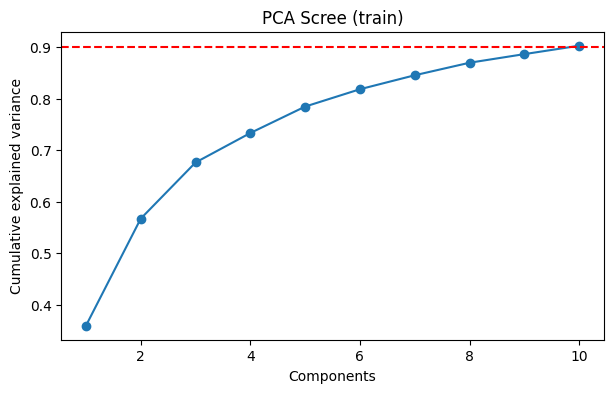

Text SVD explained variance (train): 0.379 | X_text: (100, 10)


In [58]:
# DImensionality Reduction 
from sklearn.decomposition import PCA, TruncatedSVD

# Behavioural + categorical features: PCA fitted on train, 90% variance
pca = PCA(n_components=0.90, random_state=SEED).fit(X_all[tr_idx])
X_pca = pca.transform(X_all)
print("PCA components:", pca.n_components_, "| of", X_all.shape[1], "features")

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), marker="o")
plt.axhline(0.90, color="r", ls="--"); plt.xlabel("Components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA Scree (train)"); plt.show()

# Review text: TF-IDF refit on train documents only, then SVD (LSA)
names = rest_t["Name"]
tfidf_tr = TfidfVectorizer(min_df=5, max_df=0.8, ngram_range=(1, 2), max_features=1000, sublinear_tf=True)
T_tr = tfidf_tr.fit_transform(docs.iloc[tr_idx]); T_all = tfidf_tr.transform(docs)
svd = TruncatedSVD(n_components=10, random_state=SEED).fit(T_tr)
X_text = svd.transform(T_all)
print("Text SVD explained variance (train):", svd.explained_variance_ratio_.sum().round(3), "| X_text:", X_text.shape)

##### Which dimensionality reduction technique have you used and why? 

PCA (Principal Component Analysis) was applied to the numerical and categorical features, reducing 35 features to 10 principal components while retaining 90% of the variance. For review text, Truncated SVD was used on the TF-IDF matrix to reduce it to 10 components. These techniques reduce dimensionality while preserving useful information for clustering.

### 8. Data Splitting

In [59]:
# Split your data to train and test. Choose Splitting ratio wisely.
X_train, X_test = X_all[tr_idx], X_all[te_idx]
Xp_train, Xp_test = X_pca[tr_idx], X_pca[te_idx]
print("Train:", X_train.shape, "| Test:", X_test.shape, "(80/20, stratified by cost band)")

chk = pd.DataFrame({"train": rest_model.iloc[tr_idx][["Cost", "avg_rating", "avg_compound"]].mean(),
                    "test": rest_model.iloc[te_idx][["Cost", "avg_rating", "avg_compound"]].mean()}).round(3)
print(chk)
print(pd.crosstab(rest_model["cost_band"].iloc[np.r_[tr_idx, te_idx]],
                  np.r_[["train"] * len(tr_idx), ["test"] * len(te_idx)]))

Train: (80, 35) | Test: (20, 35) (80/20, stratified by cost band)
                train     test
Cost          877.500  810.000
avg_rating      3.609    3.569
avg_compound    0.472    0.500
col_0      test  train
cost_band             
0             6     24
1             4     17
2             6     22
3             4     17


##### What data splitting ratio have you used and why?

An 80:20 train-test split was used, with 80 restaurants for training and 20 for testing. Stratified splitting based on cost bands was applied to maintain a similar distribution of restaurant price categories in both sets. This provides sufficient training data while keeping a separate test set for evaluation.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Since this is an unsupervised learning problem, there is no target variable or predefined class labels to create class imbalance. As a proxy check, the cost-band distribution was examined. The proportions were 30%, 21%, 28%, and 21%, indicating a reasonably balanced distribution without a severe imbalance.

In [60]:
# Handling Imbalanced Dataset 
# Unsupervised task: no target labels, so no class imbalance to correct
print("No target variable - resampling not applicable.")
print("Cost-band balance (proxy check):\n", rest_model["cost_band"].value_counts(normalize=True).sort_index().round(2))

No target variable - resampling not applicable.
Cost-band balance (proxy check):
 cost_band
0    0.30
1    0.21
2    0.28
3    0.21
Name: proportion, dtype: float64


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

No resampling technique was applied because the project uses unsupervised clustering and does not have target classes to balance. The cost-band distribution was checked, and stratified train-test splitting was used to maintain similar proportions of cost categories in both datasets.

## ***7. ML Model Implementation***

In [61]:
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.base import BaseEstimator, ClusterMixin
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)

# Candidate feature spaces (text components standardised on train only)
ts = StandardScaler().fit(X_text[tr_idx])
SPACES = {"PCA": X_pca, "PCA+Text": np.hstack([X_pca, ts.transform(X_text)])}
RESULTS = {}

def cluster_metrics(X, labels):
    if len(np.unique(labels)) < 2:
        return {"silhouette": np.nan, "calinski": np.nan, "davies_bouldin": np.nan, "n_clusters": 1, "min_size": len(labels)}
    return {"silhouette": silhouette_score(X, labels), "calinski": calinski_harabasz_score(X, labels),
            "davies_bouldin": davies_bouldin_score(X, labels), "n_clusters": len(np.unique(labels)),
            "min_size": np.bincount(labels).min()}

def sil_scorer(est, X, y=None):                      # held-out-fold silhouette for GridSearchCV
    lab = est.predict(X)
    return silhouette_score(X, lab) if 1 < len(np.unique(lab)) < len(X) else -1

class AggWrap(BaseEstimator, ClusterMixin):          # Agglomerative with predict() via nearest centroid
    def __init__(self, n_clusters=3, linkage="ward"):
        self.n_clusters, self.linkage = n_clusters, linkage
    def fit(self, X, y=None):
        self.labels_ = AgglomerativeClustering(n_clusters=self.n_clusters, linkage=self.linkage).fit_predict(X)
        self.centroids_ = np.vstack([X[self.labels_ == c].mean(axis=0) for c in range(self.n_clusters)])
        return self
    def predict(self, X):
        return cdist(X, self.centroids_).argmin(axis=1)

def stability(make, X, n=20):                        # ARI of 80% subsample fits vs reference fit
    rng, ref = np.random.RandomState(SEED), make().fit(X).predict(X)
    aris = []
    for _ in range(n):
        idx = rng.choice(len(X), int(0.8 * len(X)), replace=False)
        aris.append(adjusted_rand_score(ref, make().fit(X[idx]).predict(X)))
    return np.mean(aris), np.std(aris)

def evaluate_model(make, Xtr, Xte):
    est = make().fit(Xtr)
    out = {}
    for tag, X in [("train", Xtr), ("test", Xte)]:
        out.update({f"{k}_{tag}": v for k, v in cluster_metrics(X, est.predict(X)).items()})
    out["stability_ARI"], out["stability_std"] = stability(make, Xtr)
    return est, out

### ML Model - 1

In [62]:
# ML Model - 1 Implementation
# Baseline: KMeans, k and feature space chosen on TRAIN silhouette (min cluster size >= 5)
rows = []
for sp, Xs in SPACES.items():
    for k in range(2, 11):
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs[tr_idx])
        rows.append({"space": sp, "k": k, "inertia": km.inertia_, **cluster_metrics(Xs[tr_idx], km.labels_)})
sweep = pd.DataFrame(rows)
display(sweep.round(3))

ok = sweep[sweep["min_size"] >= 5]
best = ok.loc[ok["silhouette"].idxmax()]
BASE_SPACE, BASE_K = best["space"], int(best["k"])
X_space = SPACES[BASE_SPACE]
print(f"Baseline: space={BASE_SPACE}, k={BASE_K}")

# Fit the algorithm + predict (train and test)
make_base = lambda: KMeans(n_clusters=BASE_K, n_init=10, random_state=SEED)
km_base, RESULTS["KMeans (baseline)"] = evaluate_model(make_base, X_space[tr_idx], X_space[te_idx])

# Reference: silhouette of randomly shuffled labels (sanity floor)
rl = np.random.RandomState(SEED).permutation(km_base.labels_)
print("Random-label silhouette (train):", round(silhouette_score(X_space[tr_idx], rl), 3))
display(pd.DataFrame(RESULTS).T.round(3))

,space,k,inertia,silhouette,calinski,davies_bouldin,n_clusters,min_size
0,PCA,2,866.565,0.253,32.605,1.464,2,32
1,PCA,3,713.036,0.252,27.848,1.320,3,10
2,PCA,4,615.602,0.202,25.234,1.470,4,7
3,PCA,5,544.003,0.199,23.603,1.376,5,8
4,PCA,6,489.433,0.198,22.358,1.429,6,7
5,PCA,7,461.170,0.190,20.252,1.424,7,6
6,PCA,8,422.094,0.197,19.658,1.351,8,5
7,PCA,9,403.957,0.183,18.122,1.291,9,2
8,PCA,10,372.128,0.187,17.905,1.371,10,3
9,PCA+Text,2,1573.935,0.208,22.542,1.747,2,28


Baseline: space=PCA, k=2
Random-label silhouette (train): 0.011


,silhouette_train,calinski_train,davies_bouldin_train,n_clusters_train,min_size_train,silhouette_test,calinski_test,davies_bouldin_test,n_clusters_test,min_size_test,stability_ARI,stability_std
KMeans (baseline),0.253,32.605,1.464,2.0,32.0,0.202,6.514,1.374,2.0,6.0,0.875,0.096


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

K-Means clustering was used to group restaurants based on similarities in their features. Different values of K (2–10) and two feature spaces (PCA and PCA+Text) were evaluated using inertia and silhouette scores. PCA with 2 clusters performed best, with a training silhouette score of 0.253 and a test score of 0.202. The stability ARI was 0.875, indicating reasonably consistent clustering across repeated samples

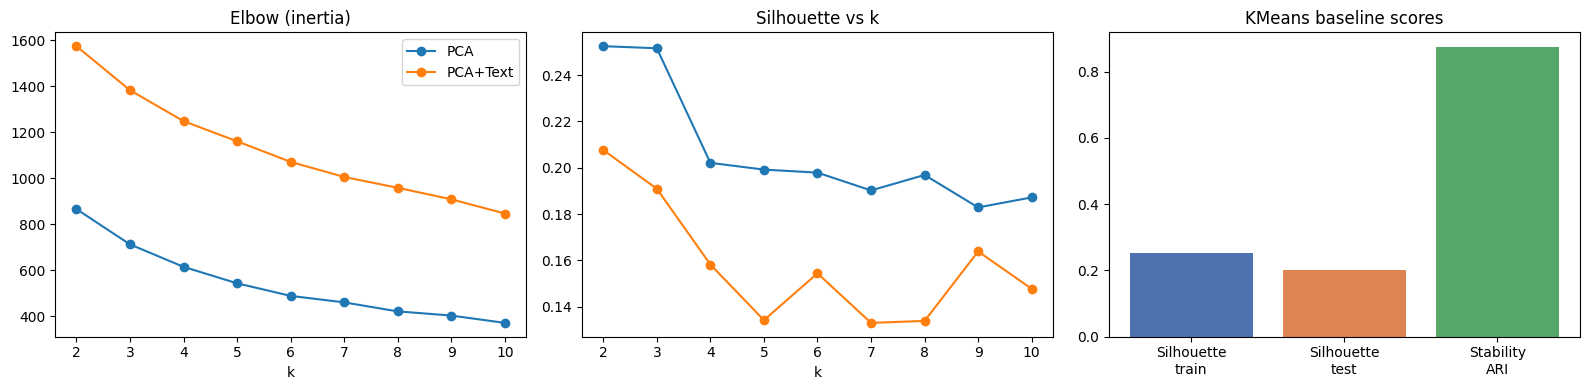

{'calinski_train': 32.605, 'davies_bouldin_train': 1.464, 'calinski_test': 6.514, 'davies_bouldin_test': 1.374}


In [63]:
# Visualizing evaluation Metric Score chart
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for sp in SPACES:
    s = sweep[sweep["space"] == sp]
    ax[0].plot(s["k"], s["inertia"], marker="o", label=sp)
    ax[1].plot(s["k"], s["silhouette"], marker="o", label=sp)
ax[0].set(title="Elbow (inertia)", xlabel="k"); ax[1].set(title="Silhouette vs k", xlabel="k"); ax[0].legend()

r = RESULTS["KMeans (baseline)"]
ax[2].bar(["Silhouette\ntrain", "Silhouette\ntest", "Stability\nARI"], [r["silhouette_train"], r["silhouette_test"], r["stability_ARI"]], color=["#4c72b0", "#dd8452", "#55a868"])
ax[2].set_title("KMeans baseline scores")
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in r.items() if "davies" in k or "calinski" in k})

#### 2. Cross- Validation & Hyperparameter Tuning

In [64]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
grid = {"n_clusters": list(range(2, 11)), "init": ["k-means++", "random"], "n_init": [10, 20]}
gs = GridSearchCV(KMeans(random_state=SEED), grid, scoring=sil_scorer,
                  cv=KFold(5, shuffle=True, random_state=SEED), n_jobs=-1, error_score=-1)

# Fit the algorithm
gs.fit(X_space[tr_idx])
print("Best params:", gs.best_params_, "| CV silhouette:", round(gs.best_score_, 3))
display(pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(8).round(3))

# Predict / evaluate tuned model
bp = gs.best_params_
make_tuned = lambda: KMeans(random_state=SEED, **bp)
km_tuned, RESULTS["KMeans (tuned)"] = evaluate_model(make_tuned, X_space[tr_idx], X_space[te_idx])
display(pd.DataFrame(RESULTS).T.round(3))

# Overfit check: train vs test silhouette gap
for n, r in RESULTS.items():
    print(f"{n}: train-test silhouette gap = {r['silhouette_train'] - r['silhouette_test']:.3f}")

Best params: {'init': 'k-means++', 'n_clusters': 2, 'n_init': 10} | CV silhouette: 0.243


,params,mean_test_score,std_test_score
0,"{'init': 'k-means++', 'n_clusters': 2, 'n_init': 10}",0.243,0.067
19,"{'init': 'random', 'n_clusters': 2, 'n_init': 20}",0.243,0.067
1,"{'init': 'k-means++', 'n_clusters': 2, 'n_init': 20}",0.243,0.067
18,"{'init': 'random', 'n_clusters': 2, 'n_init': 10}",0.242,0.068
21,"{'init': 'random', 'n_clusters': 3, 'n_init': 20}",0.218,0.024
3,"{'init': 'k-means++', 'n_clusters': 3, 'n_init': 20}",0.217,0.023
2,"{'init': 'k-means++', 'n_clusters': 3, 'n_init': 10}",0.201,0.030
20,"{'init': 'random', 'n_clusters': 3, 'n_init': 10}",0.192,0.040


,silhouette_train,calinski_train,davies_bouldin_train,n_clusters_train,min_size_train,silhouette_test,calinski_test,davies_bouldin_test,n_clusters_test,min_size_test,stability_ARI,stability_std
KMeans (baseline),0.253,32.605,1.464,2.0,32.0,0.202,6.514,1.374,2.0,6.0,0.875,0.096
KMeans (tuned),0.253,32.605,1.464,2.0,32.0,0.202,6.514,1.374,2.0,6.0,0.875,0.096


KMeans (baseline): train-test silhouette gap = 0.050
KMeans (tuned): train-test silhouette gap = 0.050


##### Which hyperparameter optimization technique have you used and why?

GridSearchCV with 5-fold cross-validation was used to tune the K-Means hyperparameters. The search evaluated the number of clusters (2–10), initialization methods (k-means++ and random), and the number of initializations (10 and 20). Silhouette score was used to identify the best combination while reducing dependence on a single train-test split.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

The tuned K-Means model selected k=2, init='k-means++', and n_init=10. However, it produced the same results as the baseline model, so there was no measurable improvement.
- Training silhouette: 0.253
- Testing silhouette: 0.202
- Stability ARI: 0.875
The tuning process confirmed that the baseline configuration was already the best-performing combination in the tested parameter grid

### ML Model - 2

In [65]:
# Scorer that penalises degenerate folds (clusters < 3 points); reused for Model 3
def sil_min(est, X, y=None):
    lab = est.predict(X)
    if len(np.unique(lab)) < 2 or np.bincount(lab).min() < 3: return -1
    return silhouette_score(X, lab)

Xtr, Xte = X_space[tr_idx], X_space[te_idx]
rows = []
for link in ["ward", "complete", "average"]:
    for k in range(2, 11):
        lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(Xtr)
        rows.append({"linkage": link, "k": k, **cluster_metrics(Xtr, lab)})
agg_sweep = pd.DataFrame(rows)
display(agg_sweep[agg_sweep["linkage"] == "ward"].round(3))

ok = agg_sweep[(agg_sweep["min_size"] >= 5) & (agg_sweep["linkage"] == "ward")]   # default ward as untuned baseline
AGG_K = int(ok.loc[ok["silhouette"].idxmax(), "k"])
print("Agglomerative baseline: ward, k =", AGG_K)

# Test restaurants are assigned to the nearest train-cluster centroid (AggWrap.predict)
make_agg = lambda: AggWrap(n_clusters=AGG_K, linkage="ward")
agg_base, RESULTS["Agglomerative (baseline)"] = evaluate_model(make_agg, Xtr, Xte)
display(pd.DataFrame(RESULTS).T.round(3))

,linkage,k,silhouette,calinski,davies_bouldin,n_clusters,min_size
0,ward,2,0.216,26.146,1.656,2,35
1,ward,3,0.234,22.953,1.297,3,7
2,ward,4,0.197,23.287,1.469,4,7
3,ward,5,0.208,22.316,1.331,5,7
4,ward,6,0.200,21.332,1.386,6,7
5,ward,7,0.177,20.113,1.470,7,7
6,ward,8,0.184,19.255,1.378,8,5
7,ward,9,0.188,18.601,1.322,9,4
8,ward,10,0.199,18.088,1.277,10,3


Agglomerative baseline: ward, k = 3


,silhouette_train,calinski_train,davies_bouldin_train,n_clusters_train,min_size_train,silhouette_test,calinski_test,davies_bouldin_test,n_clusters_test,min_size_test,stability_ARI,stability_std
KMeans (baseline),0.253,32.605,1.464,2.0,32.0,0.202,6.514,1.374,2.0,6.0,0.875,0.096
KMeans (tuned),0.253,32.605,1.464,2.0,32.0,0.202,6.514,1.374,2.0,6.0,0.875,0.096
Agglomerative (baseline),0.262,26.760,1.235,3.0,7.0,0.195,5.758,1.377,3.0,3.0,0.612,0.207


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Agglomerative Clustering was used to group restaurants based on their similarity by progressively merging data points into clusters. The Ward linkage method was selected, with 3 clusters in the baseline model. It achieved a training silhouette score of 0.262 and a test silhouette score of 0.195, with a stability ARI of 0.612. The dendrogram and silhouette scores across different linkage methods and cluster counts were used to evaluate the clustering structure.

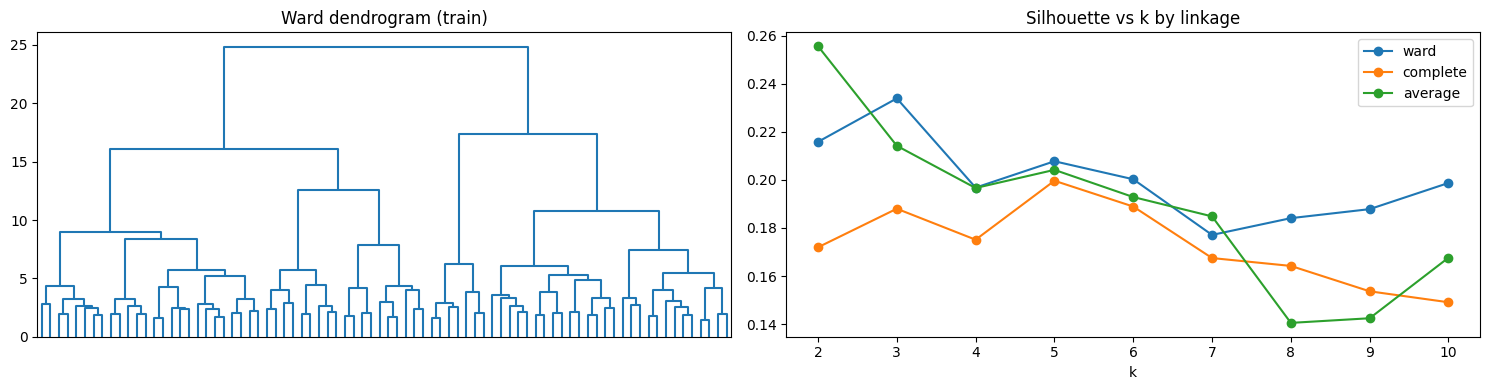

In [66]:
# Visualizing evaluation Metric Score chart
from scipy.cluster.hierarchy import linkage as sp_link, dendrogram
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
dendrogram(sp_link(Xtr, "ward"), no_labels=True, ax=ax[0], color_threshold=0); ax[0].set_title("Ward dendrogram (train)")
for link in ["ward", "complete", "average"]:
    s = agg_sweep[agg_sweep["linkage"] == link]; ax[1].plot(s["k"], s["silhouette"], marker="o", label=link)
ax[1].set(title="Silhouette vs k by linkage", xlabel="k"); ax[1].legend()
plt.tight_layout(); plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [67]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
gs_agg = GridSearchCV(AggWrap(), {"n_clusters": list(range(2, 9)), "linkage": ["ward", "complete", "average"]},
                      scoring=sil_min, cv=KFold(5, shuffle=True, random_state=SEED), n_jobs=-1, error_score=-1)
gs_agg.fit(Xtr)                                              # Fit
print("Best params:", gs_agg.best_params_, "| CV silhouette:", round(gs_agg.best_score_, 3))
display(pd.DataFrame(gs_agg.cv_results_).sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(6).round(3))

bpa = gs_agg.best_params_
agg_tuned, RESULTS["Agglomerative (tuned)"] = evaluate_model(lambda: AggWrap(**bpa), Xtr, Xte)   # Predict / evaluate
display(pd.DataFrame(RESULTS).T.round(3))

Best params: {'linkage': 'ward', 'n_clusters': 2} | CV silhouette: 0.249


,params,mean_test_score,std_test_score
0,"{'linkage': 'ward', 'n_clusters': 2}",0.249,0.061
7,"{'linkage': 'complete', 'n_clusters': 2}",0.211,0.028
14,"{'linkage': 'average', 'n_clusters': 2}",-0.267,0.600
8,"{'linkage': 'complete', 'n_clusters': 3}",-0.288,0.582
1,"{'linkage': 'ward', 'n_clusters': 3}",-0.758,0.483
15,"{'linkage': 'average', 'n_clusters': 3}",-0.767,0.466


,silhouette_train,calinski_train,davies_bouldin_train,n_clusters_train,min_size_train,silhouette_test,calinski_test,davies_bouldin_test,n_clusters_test,min_size_test,stability_ARI,stability_std
KMeans (baseline),0.253,32.605,1.464,2.0,32.0,0.202,6.514,1.374,2.0,6.0,0.875,0.096
KMeans (tuned),0.253,32.605,1.464,2.0,32.0,0.202,6.514,1.374,2.0,6.0,0.875,0.096
Agglomerative (baseline),0.262,26.760,1.235,3.0,7.0,0.195,5.758,1.377,3.0,3.0,0.612,0.207
Agglomerative (tuned),0.232,30.083,1.561,2.0,40.0,0.166,5.799,1.681,2.0,9.0,0.558,0.236


##### Which hyperparameter optimization technique have you used and why?

GridSearchCV with 5-fold cross-validation was used to tune the Agglomerative Clustering model. The search evaluated different numbers of clusters (2–8) and linkage methods (ward, complete, and average). Silhouette score was used to identify the best combination while checking how well the clusters performed across different validation folds.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

The tuning process selected n_clusters=2 and linkage='ward', with a cross-validation silhouette score of 0.249. However, the tuned model did not improve the overall performance compared with the baseline.
- Baseline test silhouette: 0.195
- Tuned test silhouette: 0.166
- Baseline stability ARI: 0.612
- Tuned stability ARI: 0.558
The baseline model performed better on the held-out test data and showed greater clustering stability.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

- Silhouette Score: Measures how well-separated and cohesive the restaurant clusters are. Higher scores indicate more distinct restaurant segments.
- Calinski-Harabasz Score: Evaluates the separation between clusters compared with the variation within clusters. Higher values indicate better-defined groups.
- Davies-Bouldin Score: Measures similarity between clusters. Lower values indicate better separation.
- Stability ARI: Measures how consistently restaurants are grouped across repeated samples. Higher values indicate more reliable segments.
These metrics help determine whether the restaurant groups are meaningful and consistent. Businesses can use the resulting segments to understand restaurant categories, customer sentiment patterns, pricing differences, and potential areas for improvement.

### ML Model - 3

In [68]:
# ML Model - 3 Implementation
rows = []
for cov in ["spherical", "diag", "tied", "full"]:
    for k in range(2, 9):
        g = GaussianMixture(n_components=k, covariance_type=cov, n_init=5, random_state=SEED, reg_covar=1e-4).fit(Xtr)
        lab = g.predict(Xtr)
        rows.append({"cov": cov, "k": k, "bic": g.bic(Xtr), "aic": g.aic(Xtr), **cluster_metrics(Xtr, lab)})
gmm_sweep = pd.DataFrame(rows)

# Baseline GMM = default 'full' covariance; k chosen by BIC (min cluster size >= 5)
ok = gmm_sweep[(gmm_sweep["cov"] == "full") & (gmm_sweep["min_size"] >= 5)]
GMM_K = int(ok.loc[ok["bic"].idxmin(), "k"])
print("GMM baseline: full covariance, k =", GMM_K)

make_gmm = lambda: GaussianMixture(n_components=GMM_K, covariance_type="full", n_init=5, random_state=SEED, reg_covar=1e-4)
gmm_base, RESULTS["GMM (baseline)"] = evaluate_model(make_gmm, Xtr, Xte)
display(pd.DataFrame(RESULTS).T.round(3))

GMM baseline: full covariance, k = 2


,silhouette_train,calinski_train,davies_bouldin_train,n_clusters_train,min_size_train,silhouette_test,calinski_test,davies_bouldin_test,n_clusters_test,min_size_test,stability_ARI,stability_std
KMeans (baseline),0.253,32.605,1.464,2.0,32.0,0.202,6.514,1.374,2.0,6.0,0.875,0.096
KMeans (tuned),0.253,32.605,1.464,2.0,32.0,0.202,6.514,1.374,2.0,6.0,0.875,0.096
Agglomerative (baseline),0.262,26.760,1.235,3.0,7.0,0.195,5.758,1.377,3.0,3.0,0.612,0.207
Agglomerative (tuned),0.232,30.083,1.561,2.0,40.0,0.166,5.799,1.681,2.0,9.0,0.558,0.236
GMM (baseline),0.248,31.939,1.493,2.0,34.0,0.172,5.229,1.552,2.0,6.0,0.704,0.234


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Gaussian Mixture Model (GMM) was used to identify restaurant clusters by modelling data as a combination of probability distributions. The baseline model selected 2 clusters using BIC, achieving a training silhouette score of 0.248 and test score of 0.172, with a stability ARI of 0.704.

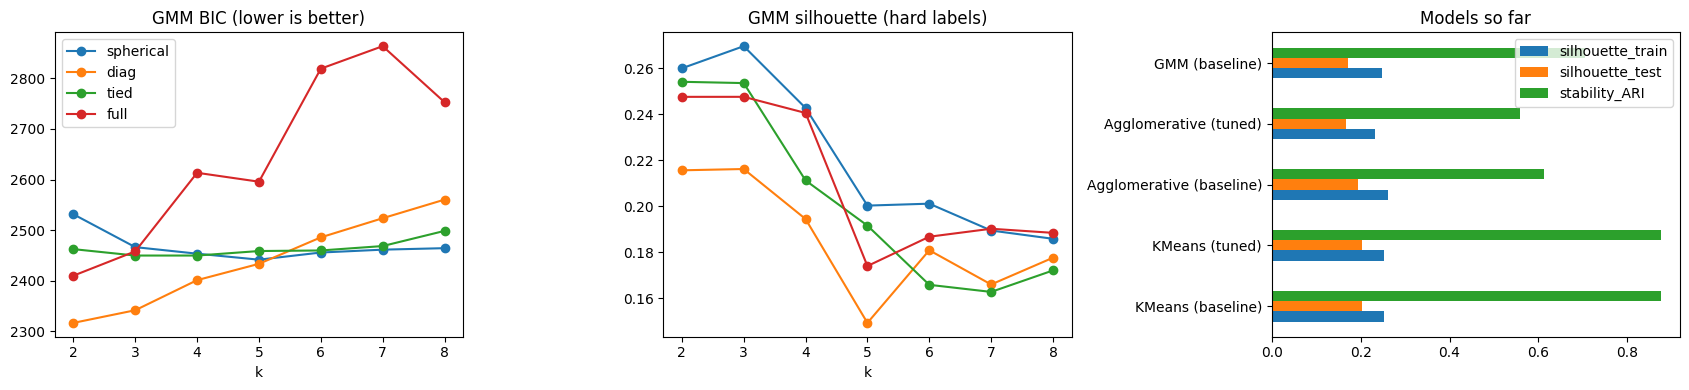

In [69]:
# Visualizing evaluation Metric Score chart
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for cov in gmm_sweep["cov"].unique():
    s = gmm_sweep[gmm_sweep["cov"] == cov]
    ax[0].plot(s["k"], s["bic"], marker="o", label=cov); ax[1].plot(s["k"], s["silhouette"], marker="o", label=cov)
ax[0].set(title="GMM BIC (lower is better)", xlabel="k"); ax[1].set(title="GMM silhouette (hard labels)", xlabel="k"); ax[0].legend()
cmp = pd.DataFrame(RESULTS).T[["silhouette_train", "silhouette_test", "stability_ARI"]]
cmp.plot.barh(ax=ax[2]); ax[2].set_title("Models so far")
plt.tight_layout(); plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [70]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
gs_gmm = GridSearchCV(GaussianMixture(random_state=SEED, reg_covar=1e-4),
                      {"n_components": list(range(2, 8)), "covariance_type": ["spherical", "diag", "tied", "full"], "n_init": [5]},
                      scoring=sil_min, cv=KFold(5, shuffle=True, random_state=SEED), n_jobs=-1, error_score=-1)
gs_gmm.fit(Xtr)                                              # Fit
print("Best params:", gs_gmm.best_params_, "| CV silhouette:", round(gs_gmm.best_score_, 3))
display(pd.DataFrame(gs_gmm.cv_results_).sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(6).round(3))

bpg = gs_gmm.best_params_
gmm_tuned, RESULTS["GMM (tuned)"] = evaluate_model(lambda: GaussianMixture(random_state=SEED, reg_covar=1e-4, **bpg), Xtr, Xte)
res_df = pd.DataFrame(RESULTS).T
display(res_df.round(3))
for n, r in RESULTS.items():
    print(f"{n}: silhouette gap (train-test) = {r['silhouette_train'] - r['silhouette_test']:.3f}")

Best params: {'covariance_type': 'spherical', 'n_components': 2, 'n_init': 5} | CV silhouette: 0.257


,params,mean_test_score,std_test_score
0,"{'covariance_type': 'spherical', 'n_components': 2, 'n_init': 5}",0.257,0.064
18,"{'covariance_type': 'full', 'n_components': 2, 'n_init': 5}",0.229,0.038
12,"{'covariance_type': 'tied', 'n_components': 2, 'n_init': 5}",0.161,0.039
6,"{'covariance_type': 'diag', 'n_components': 2, 'n_init': 5}",-0.290,0.580
19,"{'covariance_type': 'full', 'n_components': 3, 'n_init': 5}",-0.553,0.552
13,"{'covariance_type': 'tied', 'n_components': 3, 'n_init': 5}",-0.780,0.439


,silhouette_train,calinski_train,davies_bouldin_train,n_clusters_train,min_size_train,silhouette_test,calinski_test,davies_bouldin_test,n_clusters_test,min_size_test,stability_ARI,stability_std
KMeans (baseline),0.253,32.605,1.464,2.0,32.0,0.202,6.514,1.374,2.0,6.0,0.875,0.096
KMeans (tuned),0.253,32.605,1.464,2.0,32.0,0.202,6.514,1.374,2.0,6.0,0.875,0.096
Agglomerative (baseline),0.262,26.760,1.235,3.0,7.0,0.195,5.758,1.377,3.0,3.0,0.612,0.207
Agglomerative (tuned),0.232,30.083,1.561,2.0,40.0,0.166,5.799,1.681,2.0,9.0,0.558,0.236
GMM (baseline),0.248,31.939,1.493,2.0,34.0,0.172,5.229,1.552,2.0,6.0,0.704,0.234
GMM (tuned),0.260,32.471,1.411,2.0,27.0,0.203,6.084,1.295,2.0,5.0,0.916,0.073


KMeans (baseline): silhouette gap (train-test) = 0.050
KMeans (tuned): silhouette gap (train-test) = 0.050
Agglomerative (baseline): silhouette gap (train-test) = 0.067
Agglomerative (tuned): silhouette gap (train-test) = 0.066
GMM (baseline): silhouette gap (train-test) = 0.076
GMM (tuned): silhouette gap (train-test) = 0.057


##### Which hyperparameter optimization technique have you used and why?

GridSearchCV with 5-fold cross-validation was used to tune GMM. Different numbers of components (2–7), covariance types (spherical, diag, tied, full), and initialization settings were evaluated. Silhouette score was used to select the best configuration.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. The tuned GMM selected 2 components, spherical covariance, and 5 initializations.
- Training silhouette improved from 0.248 to 0.260.
- Test silhouette improved from 0.172 to 0.203.
- Stability ARI improved from 0.704 to 0.916.
The tuned model showed better clustering quality and stability than the baseline.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

,silhouette_train,silhouette_test,davies_bouldin_test,calinski_test,stability_ARI
KMeans (baseline),0.253,0.202,1.374,6.514,0.875
KMeans (tuned),0.253,0.202,1.374,6.514,0.875
Agglomerative (baseline),0.262,0.195,1.377,5.758,0.612
Agglomerative (tuned),0.232,0.166,1.681,5.799,0.558
GMM (baseline),0.248,0.172,1.552,5.229,0.704
GMM (tuned),0.260,0.203,1.295,6.084,0.916


Eligible: ['KMeans (baseline)', 'KMeans (tuned)', 'Agglomerative (baseline)', 'GMM (tuned)'] 
Selected final model: GMM (tuned)
{0: 68, 1: 32}
split    test  train
cluster             
0          15     53
1           5     27


cluster,0,1
size,68.000,32.000
Cost,1034.559,501.562
avg_rating,3.759,3.264
pct_positive,0.821,0.576
pct_negative,0.149,0.260
rating_std,1.287,1.586
avg_pictures,0.995,0.194
avg_reviewer_followers,196.897,88.285
pct_critic,0.121,0.058
n_cuisines,3.309,2.375


cluster,0,1
cuis_North_Indian,59.0,62.0
cuis_Chinese,38.0,47.0
cuis_Continental,31.0,0.0
cuis_Italian,21.0,0.0
cuis_Asian,18.0,6.0
cuis_Desserts,15.0,9.0
col_hygiene,12.0,0.0
cuis_Fast_Food,10.0,19.0
cuis_South_Indian,10.0,6.0
col_gold,10.0,0.0


Cluster 0 top terms: ['buffet', 'drink', 'dessert', 'course', 'main course', 'music', 'courteous', 'pasta', 'main', 'helpful', 'beautiful', 'floor']
Cluster 0 examples: ['Beyond Flavours', 'Paradise', 'Flechazo', 'Shah Ghouse Hotel & Restaurant', 'Over The Moon Brew Company']
Cluster 1 top terms: ['delivery', 'delivered', 'good good', 'biryani', 'packing', 'received', 'chicken biryani', 'waste money', 'not order', 'piece', 'waste', 'very bad']
Cluster 1 examples: ['Shah Ghouse Spl Shawarma', 'KFC', 'Hotel Zara Hi-Fi', 'Pakwaan Grand', '13 Dhaba']


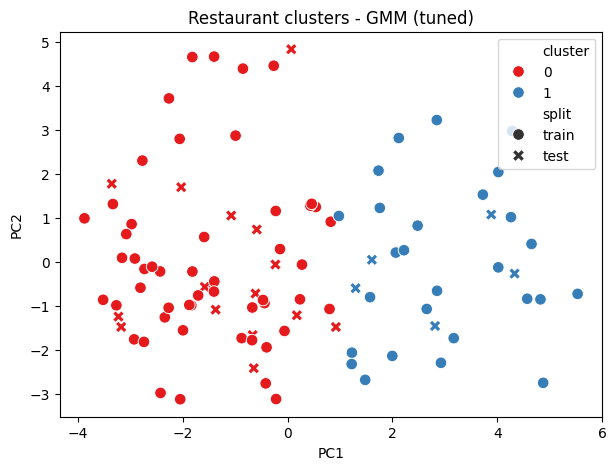

In [71]:
assert BASE_SPACE == "PCA", "Deployment pipeline below assumes the PCA feature space"
ests = {"KMeans (baseline)": km_base, "KMeans (tuned)": km_tuned, "Agglomerative (baseline)": agg_base,
        "Agglomerative (tuned)": agg_tuned, "GMM (baseline)": gmm_base, "GMM (tuned)": gmm_tuned}

# Pre-declared rule: test silhouette within 0.01 of best, then highest stability ARI
res_df = pd.DataFrame(RESULTS).T
elig = res_df[res_df["silhouette_test"] >= res_df["silhouette_test"].max() - 0.01]
FINAL_NAME = elig["stability_ARI"].idxmax()
final_est = ests[FINAL_NAME]
display(res_df[["silhouette_train", "silhouette_test", "davies_bouldin_test", "calinski_test", "stability_ARI"]].round(3))
print("Eligible:", list(elig.index), "\nSelected final model:", FINAL_NAME)

# Cluster labels for all reviewed restaurants (train + test), profiled on original scale
rest_model["cluster"] = final_est.predict(X_space)
rest_model["split"] = np.where(rest_model.index.isin(tr_idx), "train", "test")
print(rest_model["cluster"].value_counts().sort_index().to_dict())
print(pd.crosstab(rest_model["cluster"], rest_model["split"]))

PROFILE = ["Cost", "avg_rating", "pct_positive", "pct_negative", "rating_std", "avg_pictures", "avg_reviewer_followers",
           "pct_critic", "n_cuisines", "n_collections", "value_for_money"]
prof = rest_model.groupby("cluster")[PROFILE].mean().round(3)
prof.insert(0, "size", rest_model["cluster"].value_counts().sort_index())
display(prof.T)

# Cuisine mix and Zomato-collection tags per cluster (share of restaurants)
display((rest_model.groupby("cluster")[CUIS_FEATS + COL_FEATS].mean().T * 100).round(0)
        .sort_values(by=0, ascending=False).head(12))

# Distinguishing review terms per cluster (train-fitted TF-IDF, mean weight lift vs overall)
terms = np.array(tfidf_tr.get_feature_names_out()); overall = T_all.mean(axis=0).A1
for c in sorted(rest_model["cluster"].unique()):
    m = T_all[(rest_model["cluster"] == c).values].mean(axis=0).A1
    print(f"Cluster {c} top terms:", terms[np.argsort(-(m - overall))[:12]].tolist())
    print(f"Cluster {c} examples:", rest_model[rest_model["cluster"] == c].nlargest(5, "n_reviews")["Name"].tolist())

# 2-D view in PCA space
pc = X_pca[:, :2]
plt.figure(figsize=(7, 5))
sns.scatterplot(x=pc[:, 0], y=pc[:, 1], hue=rest_model["cluster"], style=rest_model["split"], palette="Set1", s=70)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title(f"Restaurant clusters - {FINAL_NAME}"); plt.show()

Silhouette Score was used to measure cluster separation, while the Davies-Bouldin Index evaluated similarity between clusters. The Calinski-Harabasz Score measured cluster compactness and separation, and Stability ARI checked consistency across repeated samples. Together, these metrics help identify meaningful and reliable restaurant segments for business decisions.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

The tuned Gaussian Mixture Model was selected as the final model. It achieved a test silhouette score of 0.203 and the highest stability ARI of 0.916. It provided a good balance of clustering quality and consistency compared with the other evaluated models.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

Surrogate CV balanced accuracy: 0.938 +/- 0.058


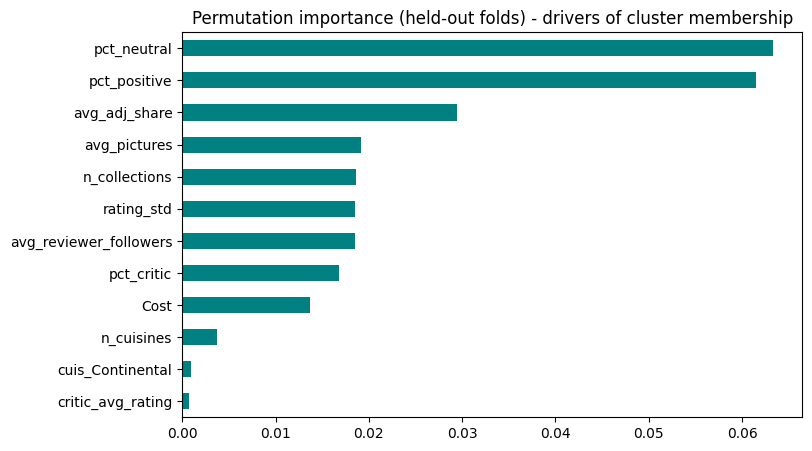

pct_neutral               0.0633
pct_positive              0.0615
avg_adj_share             0.0295
avg_pictures              0.0191
n_collections             0.0186
rating_std                0.0186
avg_reviewer_followers    0.0186
pct_critic                0.0168
Cost                      0.0137
n_cuisines                0.0037
cuis_Continental          0.0010
critic_avg_rating         0.0008
dtype: float64
SHAP skipped: No module named 'shap' (pip install shap)


In [72]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance

y_cl = rest_model["cluster"].values
X_orig = pd.DataFrame(X_all, columns=FEAT_NAMES)        # scaled original features (not PCA) -> interpretable
rf = RandomForestClassifier(n_estimators=300, max_depth=4, class_weight="balanced", random_state=SEED)

# Fidelity: how well the cluster labels are recoverable from interpretable features (CV, not in-sample)
n_sp = int(min(5, np.bincount(y_cl).min()))
fid = cross_val_score(rf, X_orig, y_cl, cv=StratifiedKFold(n_sp, shuffle=True, random_state=SEED), scoring="balanced_accuracy")
print(f"Surrogate CV balanced accuracy: {fid.mean():.3f} +/- {fid.std():.3f}")

# Permutation importance on held-out folds
rng_imp = np.zeros(len(FEAT_NAMES)); skf = StratifiedKFold(n_sp, shuffle=True, random_state=SEED)
for a, b in skf.split(X_orig, y_cl):
    m = rf.fit(X_orig.iloc[a], y_cl[a])
    rng_imp += permutation_importance(m, X_orig.iloc[b], y_cl[b], n_repeats=20, random_state=SEED,
                                      scoring="balanced_accuracy").importances_mean / n_sp
imp = pd.Series(rng_imp, index=FEAT_NAMES).sort_values(ascending=False)
plt.figure(figsize=(8, 5)); imp.head(12)[::-1].plot.barh(color="teal")
plt.title("Permutation importance (held-out folds) - drivers of cluster membership"); plt.show()
print(imp.head(12).round(4))

# SHAP (optional)
try:
    import shap
    rf.fit(X_orig, y_cl)
    sv = shap.TreeExplainer(rf).shap_values(X_orig)
    sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)
    shap.summary_plot(sv, X_orig, max_display=12)
except Exception as e:
    print("SHAP skipped:", e, "(pip install shap)")

A Random Forest classifier was used as a surrogate model to explain the clusters generated by the tuned GMM. It achieved a cross-validation balanced accuracy of 0.938 ± 0.058. Permutation importance identified pct_neutral (0.0633) and pct_positive (0.0615) as the most influential features, followed by avg_adj_share and avg_pictures. SHAP analysis could not run because the package was not installed.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [73]:
import joblib

bundle = {"model": final_est, "model_name": FINAL_NAME, "scaler": scaler, "pca": pca,
          "sel_cont": SEL_CONT, "sel_bin": SEL_BIN, "skewed": SKEWED,
          "clip_lo": lo, "clip_hi": hi, "num_feats": NUM_FEATS, "seed": SEED}
joblib.dump(bundle, "zomato_cluster_model.joblib")
rest_model.drop(columns=["Links", "Timings"], errors="ignore").to_csv("zomato_restaurant_clusters.csv", index=False)  # new file; originals untouched
print("Saved:", FINAL_NAME)

Saved: GMM (tuned)


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [74]:
# Load the File and predict unseen data.
def predict_clusters(raw, b):
    """raw: restaurant-level frame with the same engineered columns as rest_model."""
    d = raw.copy()
    d[b["num_feats"]] = d[b["num_feats"]].clip(lower=b["clip_lo"], upper=b["clip_hi"], axis=1)
    d[b["skewed"]] = np.log1p(d[b["skewed"]])
    X = np.hstack([b["scaler"].transform(d[b["sel_cont"]]), d[b["sel_bin"]].values.astype(float)])
    return b["model"].predict(b["pca"].transform(X))

loaded = joblib.load("zomato_cluster_model.joblib")
unseen = rest_model.iloc[te_idx]                                   # held-out restaurants never used to fit anything
pred = predict_clusters(unseen, loaded)
print("Loaded model:", loaded["model_name"])
print("Match with in-memory labels:", (pred == unseen["cluster"].values).mean())
print(pd.DataFrame({"Name": unseen["Name"].values, "Predicted cluster": pred}).head(10))

Loaded model: GMM (tuned)
Match with in-memory labels: 1.0
                            Name  Predicted cluster
0                       13 Dhaba                  1
1  The Lal Street - Bar Exchange                  0
2                     Desi Bytes                  1
3                  Mathura Vilas                  0
4                       Delhi-39                  1
5                     Ulavacharu                  0
6            Kritunga Restaurant                  1
7                   Dine O China                  1
8                     Pot Pourri                  0
9                      KS Bakers                  0


# **Conclusion**

This project used restaurant details and customer reviews to segment 100 restaurants based on ratings, sentiment, cost, cuisines, and other features. Among K-Means, Agglomerative Clustering, and GMM, the tuned Gaussian Mixture Model (GMM) was selected, achieving a test silhouette score of 0.203 and stability ARI of 0.916.

The model identified two distinct segments: Cluster 0 (68 restaurants), generally associated with higher costs, better ratings, and more positive reviews; and Cluster 1 (32 restaurants), with lower average costs and ratings and more delivery-related review terms. A Random Forest surrogate also highlighted neutral and positive review percentages as important features for explaining the clusters.

Finally, the selected model and preprocessing components were saved using Joblib for reuse. Overall, the project demonstrates how clustering and sentiment analysis can help identify restaurant groups and understand differences in customer experiences.